# StLearn 细胞间相互作用分析
Cell-Cell Interaction Analysis

In [ ]:
from datetime import date
print("Author: Biomamba_pudding")
print("Date:", date.today())

Author: Biomamba
Date: 2025-09-23


# 零、欢迎关注**Biomamba 生信基地**

## Biomamba，理学博士，此公众号旨在分享生信知识及科研经验与体会，目前在B站的同名账号中发布的手把手教你做单细胞测序数据分析系列视频点击量已经超过45.8W。同名微信公众号拥有超过五万的关注用户以及超过五百万的访问量。如果需要数据分析指导、生信热点全文复现、自测/数据库数据个性化分析辅导、常态化实验学习，欢迎联系客服微信[Biomamba_yunying]

![./img/Rmarkdown开头2025.jpg](http://biomamba.com:34080/free.download/file.back/biomamba/Rmarkdown%E5%BC%80%E5%A4%B42025.jpg)

# 一、写在前面

## 本教程基于Linux中的jupyter环境演示，计算资源不足的同学可参考：  
[生信分析为什么要使用服务器？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491007&idx=1&sn=8619c2bad23791b3252a1c4cb1831931&chksm=9b3f64efac48edf9c02f84959aeee9b12480736fce70c5ddb8b41d79cfc22ce590ea2cb60fba&token=1760636281&lang=zh_CN#rd)\
[足够支持你完成硕博生涯的生信环境](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511780&idx=1&sn=3acc0874f7d2fa75f1abbe7a9a9b4069&chksm=9b3cd7b4ac4b5ea27d4d53964e4a4a9fa8c806a19103729dd4ff0fa72e621411f46a251d269f&scene=21#wechat_redirect)\
[配置一个心仪的工作站(硬件+环境配置)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519707&idx=1&sn=73dcab26f9b2ed75a954327317d07112&chksm=9b3cf48bac4b7d9df5b5a432fbe70d4f9c13bc8d739aa401732614f022223d1912642a7e4bea&scene=21#wechat_redirect)\
[独享服务器，生信分析不求人](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503618&idx=1&sn=ca47ca985aa8560f6b38f15f210519e2&chksm=9b3cb652ac4b3f44292560071b7e98e2f6fa6ec03581cd882a4d59b9d7fa063a5b9ac1b923f3&scene=21#wechat_redirect)\
[为实验室准备一份生物信息学不动产](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247492383&idx=1&sn=b8d912877cb38e8d8c9084d1d9370ded&chksm=9b3c9a4fac4b135926091a8af972c45a17a2fa1f94c704779c60df5f733847036c3797894c1c&scene=21#wechat_redirect)


## Linux和Conda是我们本次课程环境搭建的基础，这两部分我们在前期推送中也有相关内容介绍。如果还没有接触过的同学可以跟随我们[十小时学会Linux](https://mp.weixin.qq.com/s/77IMXW_6QFLpbqSeMLfNJg)、[生信软件管家——conda的安装、使用、卸载](https://mp.weixin.qq.com/s/VwRHks00awHXY1tfoPNX9A)和[利用conda打包/复刻生信环境](https://mp.weixin.qq.com/s/y_NPTabHSDGPw2D-_Izs1A)教程内容提前学习一下。

## jupyter notebook作为Python的集成环境，可以逐行运行Python代码并返回结果，并且支持markerdown语法编译，可以说是一个学习Python的笔记本。jupyter notebook使用可以参考[码Python神器：jupyter notebook](https://mp.weixin.qq.com/s/bK_Ri16z8YG-1ZyRqkhM9A)。


##  Python作为本次课程**核心编程语言**。它语法简洁、库资源丰富，计算高效，是数据科学、自动化开发等领域的首选，兼顾新手入门与资深者高效需求。因此，同学们在学习这个教程前，需要有一定得Python知识，可以参考[生信Python速查手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499921&idx=1&sn=dcd6f95596e3de9bf378d850c217fe78&chksm=9b3cb9c1ac4b30d7bbd44057b181f87541f5904d24f903494ae557e768ae00c208c1b68b45c7&payreadticket=HFPtvn0Hc_3itk_RHA90ykGyhDmPMGdHlmAWpCN5_JoUcbpyL6P82ctGZm0c2MiiBCZcLU0#rd)进行快速学习

# 二、stLearn 介绍

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/stlogo.png)

## 1. 空间转录组学习平台

$\text{stLearn}$ 是一个为**高分辨率空间转录组数据**（如 $\text{Visium}$）设计的综合分析框架。它独特地结合了**组织病理学图像特征**与**基因表达数据**，以增强细胞类型识别、数据整合和下游分析。

## 2. StLearn 细胞-细胞相互作用 CCI 分析管道

$\text{stLearn}$ 的 $\text{CCI}$ 分析是其核心功能之一，旨在识别和量化组织内不同 $\text{Spot}$ 或细胞类型之间的通讯。其整体步骤如下：

### 2.1 加载配体-受体 LR 基因对

* **操作**：加载预先确定的、已知的**配体-受体 ($\text{Ligand-Receptor}$) 基因对**数据库（通常基于 $\text{CellPhoneDB}$、$\text{CellChat}$ 等数据库）。
* **目的**：定义分析中所有潜在的分子通讯通路。

### 2.2 确定显著相互作用的位点

* **操作**：基于基因表达数据，确定在**空间上邻近**的 $\text{Spot}$ 对之间，哪些 $\text{LR}$ 对表现出**显著的相互作用**（例如，通过计算 $\text{LR}$ 表达乘积和统计检验）。
* **目的**：初步筛选出在组织中分子表达水平上活跃的通讯通路。

### 2.3 计算有效点的邻居和连接

这是 $\text{stLearn}$ $\text{CCI}$ 分析的**核心空间加权步骤**：

* **步骤**：对于每一个 $\text{LR}$ 对以及每一对**发送方细胞类型** - **接收方细胞类型**组合：
    * **有效点计算**：确定参与该 $\text{LR}$ 通讯的**有效点（$\text{Spot}$）的邻居**。
    * **通讯连接**：计算**连接**这两个给定细胞类型且涉及该 $\text{LR}$ 对的有效点数量或强度。

* **目的**：量化特定 $\text{LR}$ 对在特定细胞类型组合中，其通讯信号在**空间邻域**内发生的频率和强度。

### 2.4 确定显著相互作用（统计检验）

* **操作**：通过**排列检验（$\text{Permutation}$ $\text{Test}$）**，比较观察到的 $\text{CCI}$ 强度与随机排列后的结果。
* **筛选**：从细胞类型信息排列中确定**具有 $\text{p} < 0.05$** 的统计显著相互作用。
* **目的**：排除随机发生的关联，只保留统计上可靠的细胞间通讯通路。

### 2.5 可视化 $\text{CCI}$ 结果

* **操作**：将显著的 $\text{CCI}$ 结果进行可视化。
* **形式**：通常包括**热图**（展示不同细胞类型对之间的 $\text{CCI}$ 强度）和**空间图**（将 $\text{LR}$ 活性或通讯流叠加到组织切片上）。
* **目的**：直观地展示组织内关键通讯通路的位置、强度和方向。

![](http://biomamba.com:34080/free.download/file.back/biomamba/chenao/learn2.png)

# 三、代码实操

## 1. 加载所需库

In [ ]:
import numpy as np             # 导入 NumPy，用于高性能数值计算和数组操作。
from anndata import AnnData    # 从 anndata 库中导入 AnnData 类，这是存储单细胞/空间数据的基础结构。
import h5py                    # 导入 h5py 库，用于读取和写入 HDF5 格式的文件（如 h5ad 文件）。
import stlearn as st           # 导入 stLearn 库，这是进行空间转录组分析（包括 CCI 分析）的核心工具。
import pandas as pd            # 导入 Pandas，用于高效处理表格数据 (DataFrame)。
import matplotlib.pyplot as plt # 导入 Matplotlib 的绘图模块。
import scanpy as sc            # 导入 Scanpy 库，用于进行基础的单细胞/空间数据预处理和分析。

plt.rcdefaults()
# [Matplotlib 设置] 重置 Matplotlib 的所有运行配置参数为默认值
# 目的：确保新的绘图环境干净，避免之前代码块中的自定义设置对当前绘图造成干扰

/home/chenao/miniconda3/envs/stlearn/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/home/chenao/miniconda3/envs/stlearn/lib/python3.10/site-packages/stlearn/tl/cci/het.py:206: NumbaDeprecationWarning: The keyword argument 'nopython=False' was supplied. From Numba 0.59.0 the default is being changed to True and use of 'nopython=False' will raise a warning as the argument will have no effect. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @jit(parallel=True, nopython=False)


## 2. 数据加载和预处理

Note: 这里不使用log1p数据用于受配体分析

In [ ]:
data_dir = "/data/10_spatial_communication/stlearn/data"
# [数据路径] 定义原始空间转录组数据（如 10X Visium 输出）所在的目录路径

data = st.Read10X(data_dir)
# 使用 stLearn 的 Read10X 函数，从指定目录加载基因表达矩阵、Spot 坐标等数据，创建一个 AnnData 对象

data.var_names_make_unique()
# [基因名称处理] 确保 AnnData 对象中所有基因名称（变量名）都是唯一的
# 目的：防止因重复基因名导致的后续分析错误

st.add.image(adata=data,
             imgpath=data_dir+"/spatial/tissue_hires_image.png",
             library_id="V1_Breast_Cancer_Block_A_Section_1", visium=True)
# [图像集成] 将高分辨率组织病理学图像添加到 AnnData 对象中
# - imgpath：指定图像文件的路径
# - library_id：指定数据集中唯一的库标识符
# - visium=True：指定这是 Visium 平台的数据
# 目的：将基因表达数据与 Spot 的物理位置和组织形态联系起来，为空间分析做准备

st.pp.filter_genes(data, min_cells=3)
# [基因过滤] 过滤掉那些在少于 3 个 Spot 中表达的基因
# 目的：去除低表达或噪声基因，减小数据矩阵规模

st.pp.normalize_total(data) # NOTE: no log1p
# [总计数归一化] 对每个 Spot 的基因表达进行总计数归一化（将每个 Spot 的总 UMI 计数缩放到一个固定值）
# 目的：消除测序深度差异，使 Spot 间表达谱可比
# 备注：这里只进行了归一化，**未进行 log1p 对数转换**

/home/chenao/.local/share/mamba/envs/stlearn/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/chenao/.local/share/mamba/envs/stlearn/lib/python3.10/site-packages/anndata/_core/anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Added tissue image to the object!
Normalization step is finished in adata.X


['stroma' 'basal_like_1' 'stroma' ... 'basal_like_1' 'stroma'
 'basal_like_1']
                    basal_like_2  macrophage    stroma  basal_like_1  \
AAACAAGTATCTCCCA-1      0.114847    0.153870  0.517986      0.000000   
AAACACCAATAACTGC-1      0.157768    0.004139  0.071592      0.451562   
AAACAGAGCGACTCCT-1      0.202656    0.004635  0.647263      0.003862   
AAACAGGGTCTATATT-1      0.000000    0.082156  0.003555      0.000000   
AAACAGTGTTCCTGGG-1      0.565240    0.039651  0.205373      0.119639   
...                          ...         ...       ...           ...   
TTGTTGTGTGTCAAGA-1      0.134887    0.028774  0.024245      0.353047   
TTGTTTCACATCCAGG-1      0.031501    0.893722  0.000000      0.055103   
TTGTTTCATTAGTCTA-1      0.141504    0.032159  0.105041      0.462340   
TTGTTTCCATACAACT-1      0.065008    0.000000  0.934992      0.000000   
TTGTTTGTGTAAATTC-1      0.000000    0.000000  0.000000      0.601054   

                    mesenchymal  luminal_ar  mesenchymal

AnnData object with n_obs × n_vars = 3813 × 20687
    obs: 'in_tissue', 'array_row', 'array_col', 'imagecol', 'imagerow', 'cell_type'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'spatial', 'cell_type', 'cell_type_colors'
    obsm: 'spatial'

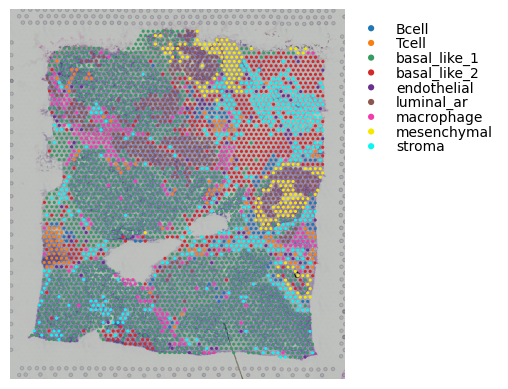

In [ ]:
spot_mixtures = pd.read_csv(data_dir+'/label_transfer_bc.csv', index_col=0, sep='\t')
# [加载数据] 从指定路径加载包含 Spot 细胞类型预测结果的文件 (label_transfer_bc.csv)，并使用第一列作为索引

labels = spot_mixtures.loc[:,'predicted.id'].values.astype(str)
# [提取标签] 提取 'predicted.id' 列作为每个 Spot 的主要（占主导地位的）细胞类型标签

spot_mixtures = spot_mixtures.drop(['predicted.id','prediction.score.max'],
                                   axis=1)
# [删除冗余列] 从 spot_mixtures DataFrame 中删除主要标签 ('predicted.id') 和最大预测得分 ('prediction.score.max') 列
# 目的：spot_mixtures 应该只保留每种细胞类型的分数

spot_mixtures.columns = [col.replace('prediction.score.', '')
                           for col in spot_mixtures.columns]
# [清理列名] 移除列名前缀 'prediction.score.'，使列名更简洁（例如，将 'prediction.score.Tcell' 变为 'Tcell'）

# 查看数据格式
print(labels)
print(spot_mixtures)
print('Spot mixture order correct?: ',
      np.all(spot_mixtures.index.values==data.obs_names.values)) # 检查索引与data.obs_names是否一致

# 保证data数据一致
data.obs['cell_type'] = labels # 添加主要细胞类型标签
data.obs['cell_type'] = data.obs['cell_type'].astype('category') # 将cell_type列转换为类别类型
data.uns['cell_type'] = spot_mixtures # 添加细胞类型混合比例矩阵

# 可视化主要细胞类型在空间中的分布
st.pl.cluster_plot(data, use_label='cell_type')

In [ ]:
对于上述细胞类型信息，请注意这些结果是使用 Seurat 生成的

没有必要在每个位置都使用细胞类型评分，你也可以使用其他的类型标签

## 3. 运行受配体分析

In [ ]:
# 加载stlearn所配受配体数据库 (from NATMI)
lrs = st.tl.cci.load_lrs(['connectomeDB2020_lit'], species='human')
# [加载数据库] 使用 stLearn 加载 LR 数据库
# - ['connectomeDB2020_lit']: 指定使用基于 NATMI 的 connectomeDB2020 文献策展数据库
# - species='human': 指定数据库适用于人类物种（与输入数据物种需一致）

print(len(lrs))
# 输出加载的 LR 对的数量

# 运行分析
st.tl.cci.run(
    data, 
    lrs,
    # [LR 数据库] 使用上一步加载的 LR 相互作用对列表
    min_spots = 20, 
    # [Spot 过滤] 过滤掉 LR 对分数在少于 20 个 Spot 中有记录的 LR 对
    # 目的：确保只分析在组织中有足够表达和通讯证据的通路
    distance=None, 
    # [空间邻域] 设置空间距离模式
    # - None：默认设置为计算 Spot 及其所有紧邻邻居之间的通讯（核心空间感知模式）
    # - distance=0：则为 Spot 内部通讯模式
    n_pairs=100, 
    # [随机配对数] 用于统计检验（排列检验）的随机配对次数
    # - 注意：示例中设置为 100，通常建议在实际分析中使用更高的值（如 10,000）以确保统计稳健性
    n_cpus=10, 
    # [并行计算] 指定用于并行计算的 CPU 核心数
)
# [核心 CCI 计算] stLearn 执行空间加权的细胞间通讯分析。它量化每个 LR 对在空间邻近 Spot 之间的相互作用强度，并进行排列检验以确定显著性

lr_info = data.uns['lr_summary'] 
# [提取摘要] 从 AnnData 对象的 .uns 槽位中提取 CCI 分析结果的摘要 DataFrame
# - lr_summary：包含 LR 对的排名，通常根据显著通讯 Spot 的数量进行排序
print('\n', lr_info)
# [输出]LR 对摘要 DataFrame 的内容
# 目的：快速查看哪些 LR 对在组织中表现出最显著的空间通讯活性

2293
Calculating neighbours...
0 spots with no neighbours, 6 median spot neighbours.
Spot neighbour indices stored in adata.obsm['spot_neighbours'] & adata.obsm['spot_neigh_bcs'].
Altogether 1444 valid L-R pairs


Generating backgrounds & testing each LR pair...: 100%|██████████ [ time left: 00:00 ]  


Storing results:

lr_scores stored in adata.obsm['lr_scores'].
p_vals stored in adata.obsm['p_vals'].
p_adjs stored in adata.obsm['p_adjs'].
-log10(p_adjs) stored in adata.obsm['-log10(p_adjs)'].
lr_sig_scores stored in adata.obsm['lr_sig_scores'].

Per-spot results in adata.obsm have columns in same order as rows in adata.uns['lr_summary'].
Summary of LR results in adata.uns['lr_summary'].

                n_spots  n_spots_sig  n_spots_sig_pval
ANGPTL2_ITGB1     2687           13               285
VCAN_ITGB1        3468           12               200
LGALS1_ITGB1      3744           11               191
THBS2_ITGB1       3440           11               264
LAMB1_ITGB1       3290           11               247
...                ...          ...               ...
ADM_RAMP3          389            0               182
AFDN_EPHA7          61            0                57
ZP3_EGFR           199            0               131
ZP3_MERTK          350            0               172
ACE_BDKRB

## 4. P值矫正

下面可以使用不同的方法调整 p 值；p 值已经通过运行 st.tl.cci.run 进行了校正。这是论文使用的方法，也是下面函数的默认值。

correct_axis 之间的差值是根据每个点 (LR) 测试的点数、每个 LR (spot) 测试的点数或不调整 (None) 进行调整的

In [ ]:
st.tl.cci.adj_pvals(
    data, 
    correct_axis='spot',
    # [校正维度] 关键参数：指定 p 值校正的维度为 'spot'
    # 目的：对每个 LR 对在所有 Spot 间通讯的 p 值进行校正。这意味着，对于一个特定的 LR 对，所有可能的 Spot-Spot 相互作用的 p 值被视为一个多重检验组进行校正
    pval_adj_cutoff=0.05, 
    # [显著性阈值] 设置校正后 p 值（q 值）的显著性阈值为 0.05。只有低于此阈值的相互作用才被认为是显著的
    adj_method='fdr_bh'
    # [校正方法] 关键参数：指定使用 'fdr_bh' (False Discovery Rate - Benjamini/Hochberg) 方法进行 p 值校正
    # 目的：控制错误发现率 (FDR)，以减少在大量假设检验（LR 对 x Spot 对）中出现假阳性的可能性
)
# 作用：计算并存储校正后的 p 值（通常称为 q 值）。这个步骤是确保 CCI 结果具有统计稳健性的核心环节

Updated adata.uns[lr_summary]
Updated adata.obsm[lr_scores]
Updated adata.obsm[lr_sig_scores]
Updated adata.obsm[p_vals]
Updated adata.obsm[p_adjs]
Updated adata.obsm[-log10(p_adjs)]


/home/chenao/.local/share/mamba/envs/stlearn/lib/python3.10/site-packages/stlearn/tl/cci/analysis.py:424: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[11 10 10 ...  0  0  0]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  adata.uns["lr_summary"].loc[:, "n_spots_sig"] = lr_counts
/home/chenao/.local/share/mamba/envs/stlearn/lib/python3.10/site-packages/stlearn/tl/cci/analysis.py:425: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[201 124 155 ... 129 169 228]' has dtype incompatible with int32, please explicitly cast to a compatible dtype first.
  adata.uns["lr_summary"].loc[:, "n_spots_sig_pval"] = lr_counts_pval


## 5. 按显著程度可视化 LR 的整体排名

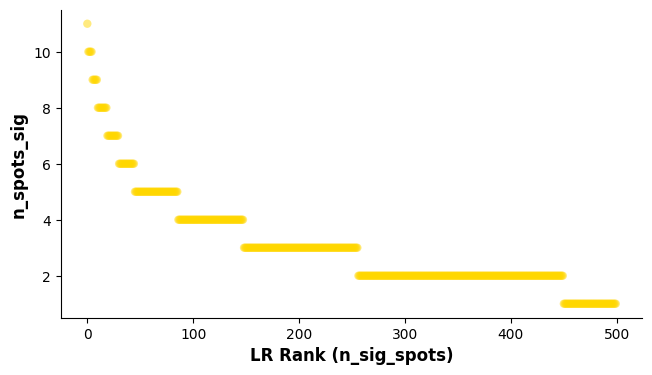

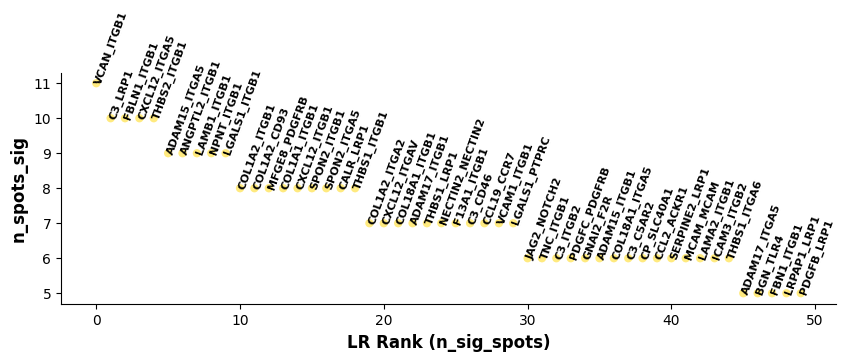

In [ ]:
# 根据显著性对spot进行排列
st.pl.lr_summary(data, n_top=500)
# 绘制 LR 对的摘要图
# - data: 输入包含 CCI 结果（包括校正后的 p 值）的 AnnData 对象
# - n_top=500: 指定在图中显示最显著的 500 个 LR 相互作用对
# 目的：展示一个相对宏观的视图，快速评估哪些 LR 通路在组织中具有广泛的显著性
# 图表形式通常是条形图或点图，按显著性（例如，具有显著 Spot 数量）降序排列 LR 对

st.pl.lr_summary(data, n_top=50, figsize=(10,3))
# 再次绘制 LR 对的摘要图，但聚焦于更少的 LR 对
# - n_top=50: 仅显示最显著的 50 个 LR 相互作用对
# - figsize=(10,3): 设置图表的尺寸为 10x3 英寸，使其更宽且紧凑，便于查看细节
# 目的：提供一个聚焦的视图，用于识别和记录组织中最强、最关键的 50 个通讯通路

## 6. 判定绘图质量：LR 热点与表达水平和频率的相关性评估

$\text{LR}$ 分析的一个关键方面是在调用**显著热点**时，要确保其不会被$\text{LR}$ 对的固有高表达水平或**高表达频率**所主导。理想情况下，一个 $\text{CCI}$ 工具的统计检验应该能够将高表达和高频率的影响解耦。

**核心假设**

一个高质量的 $\text{CCI}$ 统计分析（例如，使用了足够的排列检验）应该满足以下条件：

* 在最终的**显著 $\text{LR}$ 对列表**（“热点”）中，这些对的显著性**与它们的平均表达水平或表达频率之间几乎没有相关性**。

如果图中显示**$\text{LR}$ 对的热点与表达水平和表达频率之间几乎没有相关性**，则说明我们的统计检验是有效的，能够可靠地识别出真正的空间通讯信号。

**质量检查与改进建议**

以下代码允许我们检查并确认情况是否如此：

* **如果相关性很低**：说明 $\text{p}$ 值或 $\text{q}$ 值的计算是稳健的。
* **如果相关性较高**：则可能表明统计检验不足，**可能需要更多的排列次数**（例如，将 $\text{n\_pairs}$ 从默认值增加到 $10,000$ 或更高），以获得更可靠的背景模型，从而更好地控制表达偏差。

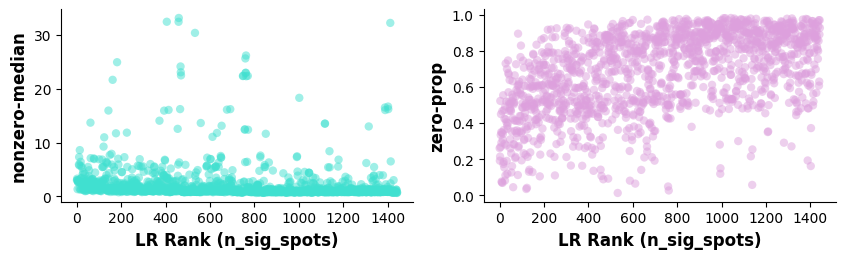

In [ ]:
st.pl.lr_diagnostics(data, figsize=(10,2.5))
# 调用 stLearn 的 LR 诊断函数
# - data: 输入包含 CCI 分析结果的 AnnData 对象
# - figsize=(10,2.5): 设置图表的尺寸为 10x2.5 英寸，使其宽度适中
#
# 作用：该函数通常生成两个关键的诊断散点图：
# 1. 显著性得分 (y 轴) vs. LR 对的平均表达水平 (x 轴)
# 2. 显著性得分 (y 轴) vs. LR 对的表达频率 (x 轴，即表达 LR 对的 Spot 百分比)
#
# 目的：
# 理想情况下，这些图应该显示：
# - 顶部显著的 LR 对（通常用颜色标记）均匀分布在 x 轴上
# - 没有明显的正相关性。
# 如果观察到强烈的正相关，则表明显著性结果可能被高表达或高频率偏差驱动，需要增加排列次数（n_pairs）来提高统计稳健性

左图：LR 表达水平 (LR 对中基因的非零点平均中位表达) 与 LR 排名之间的关系。

右图：LR 表达频率 (LR 对中每个基因零点的平均比例) 与 LR 排名之间的关系。

在这种情况下，LR 表达频率与显著斑点数量之间存在弱相关性，表明 n_pairs 参数应设置得更高，以创建更准确的背景分布 (上述纸质版本中使用了 10,000 个 n_pairs 参数)。

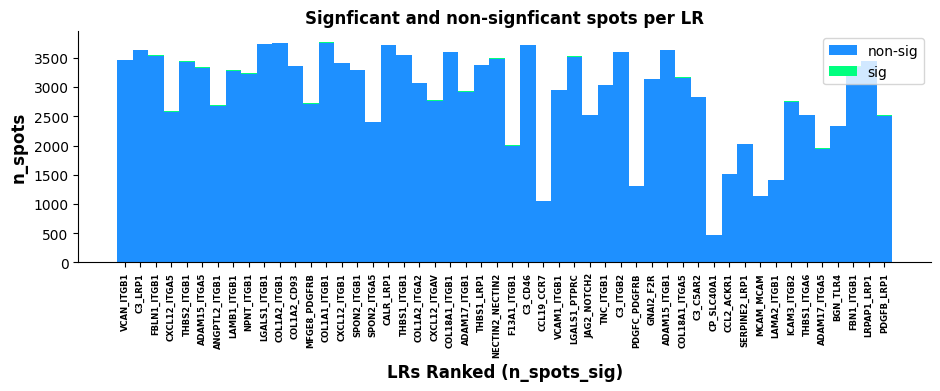

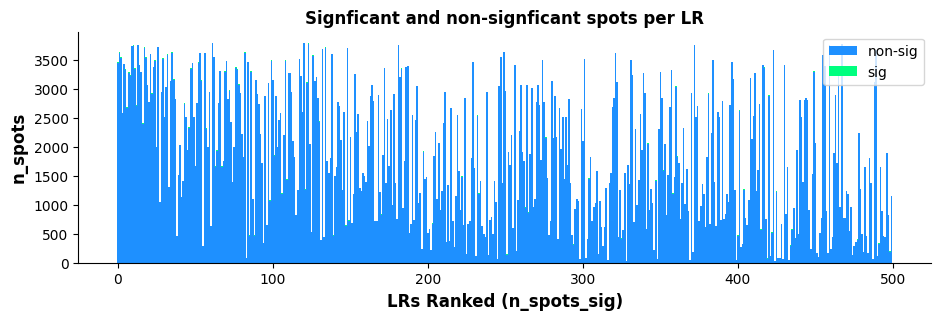

In [ ]:
st.pl.lr_n_spots(data, n_top=50, figsize=(11, 3),
                 max_text=100)
# 可视化 LR 对在组织中具有统计显著通讯的 Spot 数量
# - data: 输入包含 CCI 结果（已进行 p 值校正）的 AnnData 对象
# - n_top=50: 仅显示具有最多显著 Spot 数量的 50 个 LR 对
# - figsize=(11, 3): 设置图表尺寸，使其更宽，便于显示 LR 对名称
# - max_text=100: 设置 LR 对标签的最大文本长度，防止标签过长
# 目的：聚焦于组织中最活跃、空间分布最广泛的关键通讯通路

st.pl.lr_n_spots(data, n_top=500, figsize=(11, 3),
                 max_text=100)
# 再次可视化，展示更广泛的 LR 对
# - n_top=500: 显示具有最多显著 Spot 数量的 500 个 LR 对
# 目的：提供一个更全面的视图，展示所有具有中等到高显著性的 LR 通路

上述方框图显示了 y 轴上每个 LR 的配体 - 受体评分点数，以及 x 轴上的 LR 排名。条形区域由显著 (绿色) 和不显著 (蓝色) 的点分层。

虽然与散点图相比，这个图的趋势没有那么明显，但似乎与更高频率的 LR 对和 LR 排名存在一定的相关性；上面的 n_pairs 参数应该设置得更高。

In [ ]:
# 保存处理后的数据
data.write('/data/10_spatial_communication/stlearn/process_data.h5ad')

## 7. 下游可视化

In [ ]:
我们是否将顶部 LR 对中基因的生物学富集视为显著的关注现象（也可以基于研究目的聚焦感兴趣的生物学通路）

In [ ]:
# 加载处理后的数据
data = sc.read_h5ad('/home/chenao/jupyter_home/downstream/process/neighbor_analysis/stlearn/process_data.h5ad')

In [ ]:
%%bash

# 后续分析会调用R的函数
# 查询 R 路径
which Rscript

/home/chenao/miniconda3/envs/stlearn/bin/Rscript


In [ ]:
## 运行GO分析，这部分需要配置好R环境，包含 clusterProfiler, org.Hs.eg.db, org.Mm.eg.db包
import os
r_path = "/usr/lib/R"
st.tl.cci.run_lr_go(data, r_path)

R callback write-console: 
  
R callback write-console: clusterProfiler v4.14.6 Learn more at https://yulab-smu.top/contribution-knowledge-mining/

Please cite:

G Yu. Thirteen years of clusterProfiler. The Innovation. 2024,
5(6):100722
  
R callback write-console: 
Attaching package: ‘clusterProfiler’

  
R callback write-console: The following object is masked from ‘package:stats’:

    filter

  
R callback write-console: Loading required package: AnnotationDbi
  
R callback write-console: Loading required package: stats4
  
R callback write-console: Loading required package: BiocGenerics
  
R callback write-console: 
Attaching package: ‘BiocGenerics’

  
R callback write-console: The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

  
R callback write-console: The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,


GO results saved to adata.uns['lr_go']


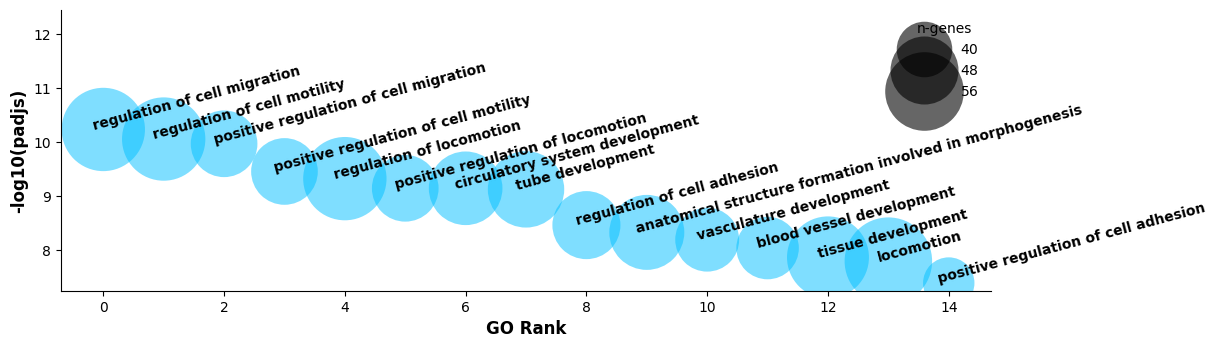

In [ ]:
# 按显著程度可视化 LR 的整体排名
st.pl.lr_go(data,
    lr_text_fp={'weight': 'bold', 'size': 10}, 
    # [LR 文本格式] 设置 LR 对名称文本的格式：字体加粗 (bold)，大小为 10
    rot=15, 
    # [文本旋转] 将 LR 对名称标签旋转 15 度，以防止标签重叠
    figsize=(12,3.65), 
    # [图表尺寸] 设置图表的宽度为 12 英寸，高度为 3.65 英寸  
    n_top=15, 
    # [顶部 LR 对数] 仅显示排名最靠前（最显著）的 15 个 LR 相互作用对
    show=False
)
# 作用：生成一个图表（通常是富集柱状图或排名的点图），用于展示前 15 个最显著 LR 对的排名，可能与其富集的生物学功能（如 GO term 或信号通路）相关联
# 目的：宏观地总结组织中最活跃的分子通讯机制

### 7.1. 受配体对的统计可视化

在 $\text{stLearn}$ 的细胞-细胞相互作用 ($\text{CCI}$) 分析完成后，结果中包含针对每个 $\text{Spot}$ 和每个 $\text{LR}$ 对计算出的详细统计数据。这些数据存储在 $\text{AnnData}$ 对象的 **$\text{.obsm}$** 槽位中，用于后续的**空间背景可视化**。

关键数据存储在 $\text{.obsm}$ 中

用于绘图（例如，通过 $\text{Lr\_result\_plot}$ 函数）的不同值都存储在 $\text{AnnData}$ 对象的 **$\text{.obsm}$** 槽位中，包含以下几类关键信息：

| 存储键（通常在 $\text{.obsm}$ 中） | 描述 | 目的 |
| :--- | :--- | :--- |
| $\text{lr\_scores}$ | 原始的 $\text{LR}$ 相互作用得分。 | 量化 $\text{Spot}$ 邻域内的通讯强度。 |
| $\text{p\_vals}$ | 原始的 $\text{p}$ 值。 | 评估 $\text{LR}$ 相互作用的原始统计显著性。 |
| $\text{p\_adjs}$ | 校正后的 $\text{p}$ 值（$\text{q}$ 值）。 | 用于多重假设检验校正后的统计稳健性。 |
| $\text{-log10(p\_adjs)}$ | **常用绘图值。**值越大，通讯越显著。 |
| $\text{lr\_sig\_scores}$ | **显著性评分**，通常是二元的 ($\text{0}$ 或 $\text{1}$)。 | 标识 $\text{Spot}$ 是否存在显著的 $\text{LR}$ 通讯热点。 |

Lr_result_plot 的作用

$\text{Lr\_result\_plot}$ 函数利用上述 $\text{.obsm}$ 中的数据，将特定 $\text{LR}$ 对的统计信息**叠加到组织空间图像或 $\text{Spot}$ 坐标上**。这有助于用户直观地识别：

* **通讯热点**：在统计上显著参与该 $\text{LR}$ 对通讯的特定空间区域。
* **强度分布**：通讯得分在整个组织中的空间变化模式。

In [6]:
best_lr = data.uns['lr_summary'].index.values[0] # 可以选择其中一个值来观察

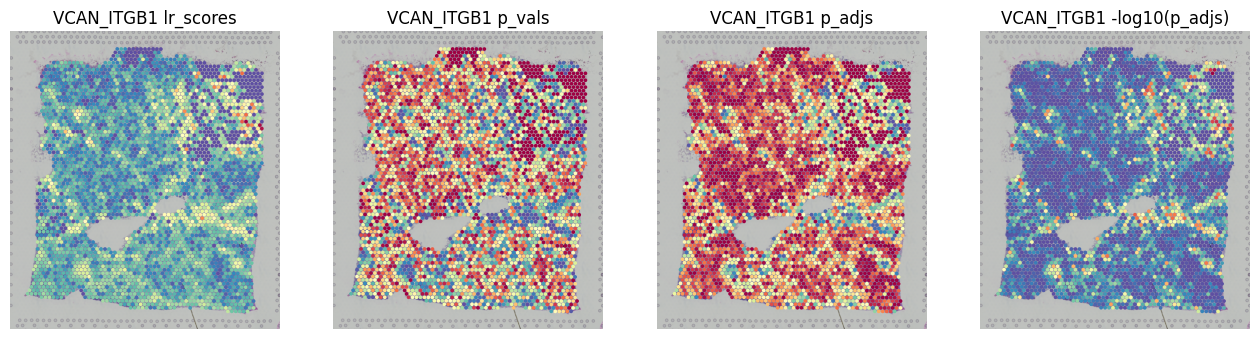

In [ ]:
stats = ['lr_scores', 'p_vals', 'p_adjs', '-log10(p_adjs)']
# [统计数据列表] 定义要可视化的统计指标列表。这些数据通常存储在 AnnData.obsm 中
fig, axes = plt.subplots(ncols=len(stats), figsize=(16,6))
# [创建子图] 创建一个 Matplotlib 画布，包含 1 行 4 列子图（与 stats 列表长度相同），用于并排展示
for i, stat in enumerate(stats):
# [循环绘制] 遍历四个统计指标
    st.pl.lr_result_plot(data, 
                         use_result=stat, 
                         # [使用结果] 指定使用当前循环的统计指标 (stat) 作为 Spot 的颜色值
                         use_lr=best_lr, 
                         # [目标 LR 对] 指定要可视化的单个 LR 对 ('best_lr')
                         show_color_bar=False, 
                         # [颜色条] 不显示颜色条，使子图更紧凑
                         ax=axes[i])
                         # [指定轴] 将图表绘制到当前的子图轴上
    axes[i].set_title(f'{best_lr} {stat}')
    # [设置标题] 设置子图标题，格式为 "LR对名称 统计指标名称"

Text(0.5, 1.0, 'VCAN_ITGB1 lr_sig_scores')

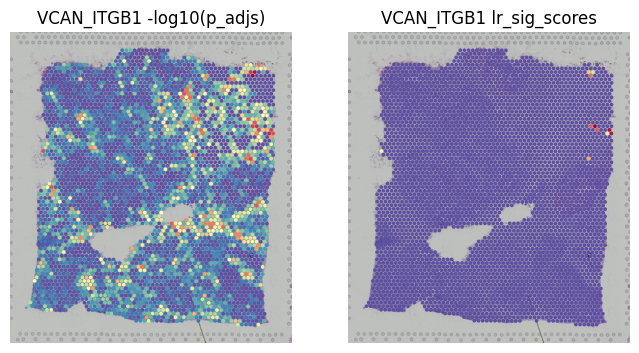

In [ ]:
fig, axes = plt.subplots(ncols=2, figsize=(8,6))
# [创建子图] 创建一个 Matplotlib 画布，包含 1 行 2 列子图，用于并排显示结果
st.pl.lr_result_plot(data, 
    use_result='-log10(p_adjs)', 
    # [使用结果] 关键：使用 -log10(p_adjs) 值作为 Spot 的颜色强度
    # 目的：值越高，表示该 Spot 的 LR 通讯在统计上越显著
    use_lr=best_lr, 
    # [目标 LR 对] 指定要可视化的特定 LR 对
    show_color_bar=False, 
    # [颜色条] 不显示颜色条
    ax=axes[0])
axes[0].set_title(f'{best_lr} -log10(p_adjs)')
# [标题] 设置子图标题，显示该 LR 对的显著性强度分布

st.pl.lr_result_plot(data, 
    use_result='lr_sig_scores', 
    # [使用结果] 关键：使用 lr_sig_scores（LR 显著性得分）
    # 目的：这是一个二元（或准二元）值，用于直接显示哪些 Spot 被判定为具有显著 LR 通讯的“热点”
    use_lr=best_lr, 
    # [目标 LR 对] 指定要可视化的特定 LR 对
    show_color_bar=False, 
    # [颜色条] 不显示颜色条
    ax=axes[1])
axes[1].set_title(f'{best_lr} lr_sig_scores')
# [标题] 设置子图标题，显示该 LR 对的显著热点位置

axes[0].set_title(f'{best_lr} -log10(p_adjs)')
axes[1].set_title(f'{best_lr} lr_sig_scores')

### 7.2 LR 解释结果可视化

这些可视化图像旨在帮助解释细胞通讯的方向性

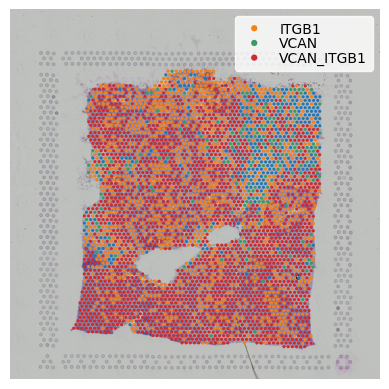

In [9]:
st.pl.lr_plot(data, best_lr, inner_size_prop=0.1, outer_mode='binary', pt_scale=5,
              use_label=None, show_image=True,
              sig_spots=False)

/home/chenao/miniconda3/envs/stlearn/lib/python3.10/site-packages/stlearn/pl/cci_plot.py:758: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[f"{lr}_binary_labels"] = lr_binary_labels


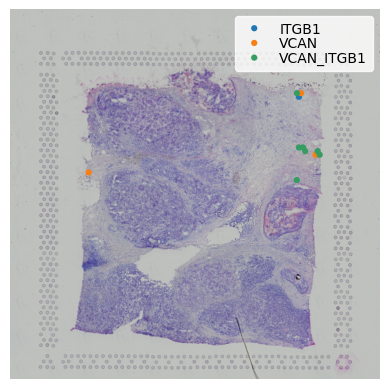

In [10]:
st.pl.lr_plot(data, best_lr, outer_size_prop=1, outer_mode='binary', pt_scale=20,
              use_label=None, show_image=True,
              sig_spots=True)

受体为绿色，配体为红色。内点是受体，外点是配体

帮助了解配体 / 受体在哪里以及表达程度如何，受体存在细胞表面，配体也从细胞表面分泌出来

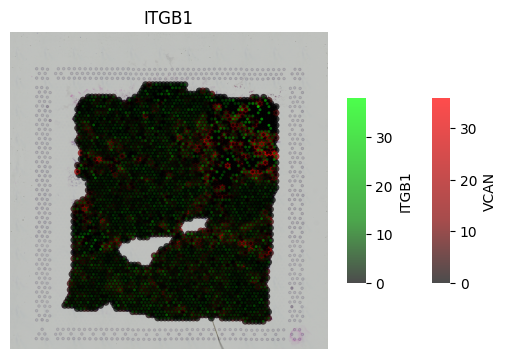

In [11]:
# 全部信号
st.pl.lr_plot(data, best_lr,
              inner_size_prop=0.04, middle_size_prop=.07, outer_size_prop=.4,
              outer_mode='continuous', pt_scale=60,
              use_label=None, show_image=True,
              sig_spots=False)

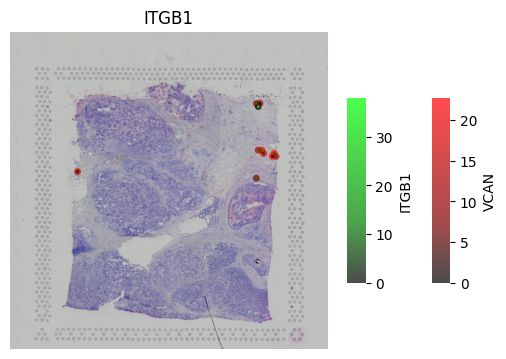

In [12]:
# 仅仅显著信号
st.pl.lr_plot(data, best_lr,
              inner_size_prop=0.04, middle_size_prop=.07, outer_size_prop=.4,
              outer_mode='continuous', pt_scale=60,
              use_label=None, show_image=True,
              sig_spots=True)

这只有在放大并想同时显示细胞信息和交互方向时才有用

/home/chenao/miniconda3/envs/stlearn/lib/python3.10/site-packages/stlearn/pl/cci_plot.py:758: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[f"{lr}_binary_labels"] = lr_binary_labels


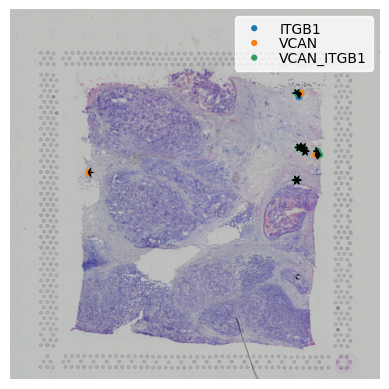

In [13]:
st.pl.lr_plot(data, best_lr,
              inner_size_prop=0.08, middle_size_prop=.3, outer_size_prop=.5,
              outer_mode='binary', pt_scale=50,
              show_image=True, arrow_width=10, arrow_head_width=10,
              sig_spots=True, show_arrows=True)

我们还可以可视化配体或受体与显性斑点细胞类型同时表达 / 共表达的位置。

外斑显示配体 (红色)、受体 (绿色) 和共表达 (蓝色) 的表达。内斑由显性spot细胞类型染色。

/home/chenao/miniconda3/envs/stlearn/lib/python3.10/site-packages/stlearn/pl/cci_plot.py:758: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[f"{lr}_binary_labels"] = lr_binary_labels


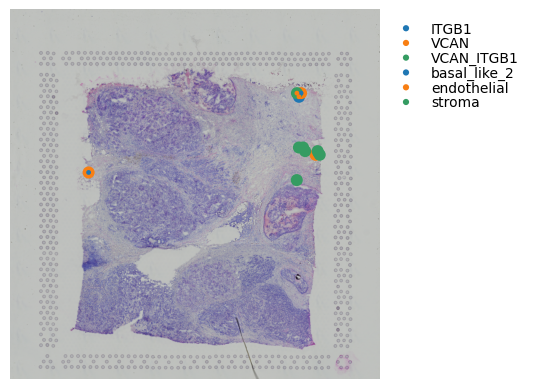

In [14]:
st.pl.lr_plot(data, best_lr,
              inner_size_prop=0.08, middle_size_prop=.3, outer_size_prop=.5,
              outer_mode='binary', pt_scale=150,
              use_label='cell_type', show_image=True,
              sig_spots=True)

### 7.3 预测重要的 CCIs

随着 LR 相互作用显著区域的建立，现在可以确定显著相互作用的细胞类型

In [ ]:
# 运行细胞类型和 LR 表达热点的共同发生率计数 #
st.tl.cci.run_cci(data, 'cell_type', # 需要的spot信息
                  min_spots=3, # 至少在n个细胞中观察到LR对
                  spot_mixtures=True, # 如果 True 将使用标签转换评分, 否则将使用主要标签
                  cell_prop_cutoff=0.2, # 因此，如果 score>cell_prop_cutoff, 光点可以有多种单元格类型
                  sig_spots=True, # 只考虑那些 LR 得分显著的区域
                  n_perms=100 # 获取背景信息的细胞信息排列，建议约 1000
                 )

Getting cached neighbourhood information...
Getting information for CCI counting...


Counting celltype-celltype interactions per LR and permuting 100 times.: 100%|██████████ [ time left: 00:00 ]

Significant counts of cci_rank interactions for all LR pairs in data.uns[lr_cci_cell_type]
Significant counts of cci_rank interactions for each LR pair stored in dictionary data.uns[per_lr_cci_cell_type]


### 7.4 检查相互作用和细胞类型频率相关性

如果排列次数足够，下图应该显示很少甚至没有相关性；否则，建议增加上面的 n_perm

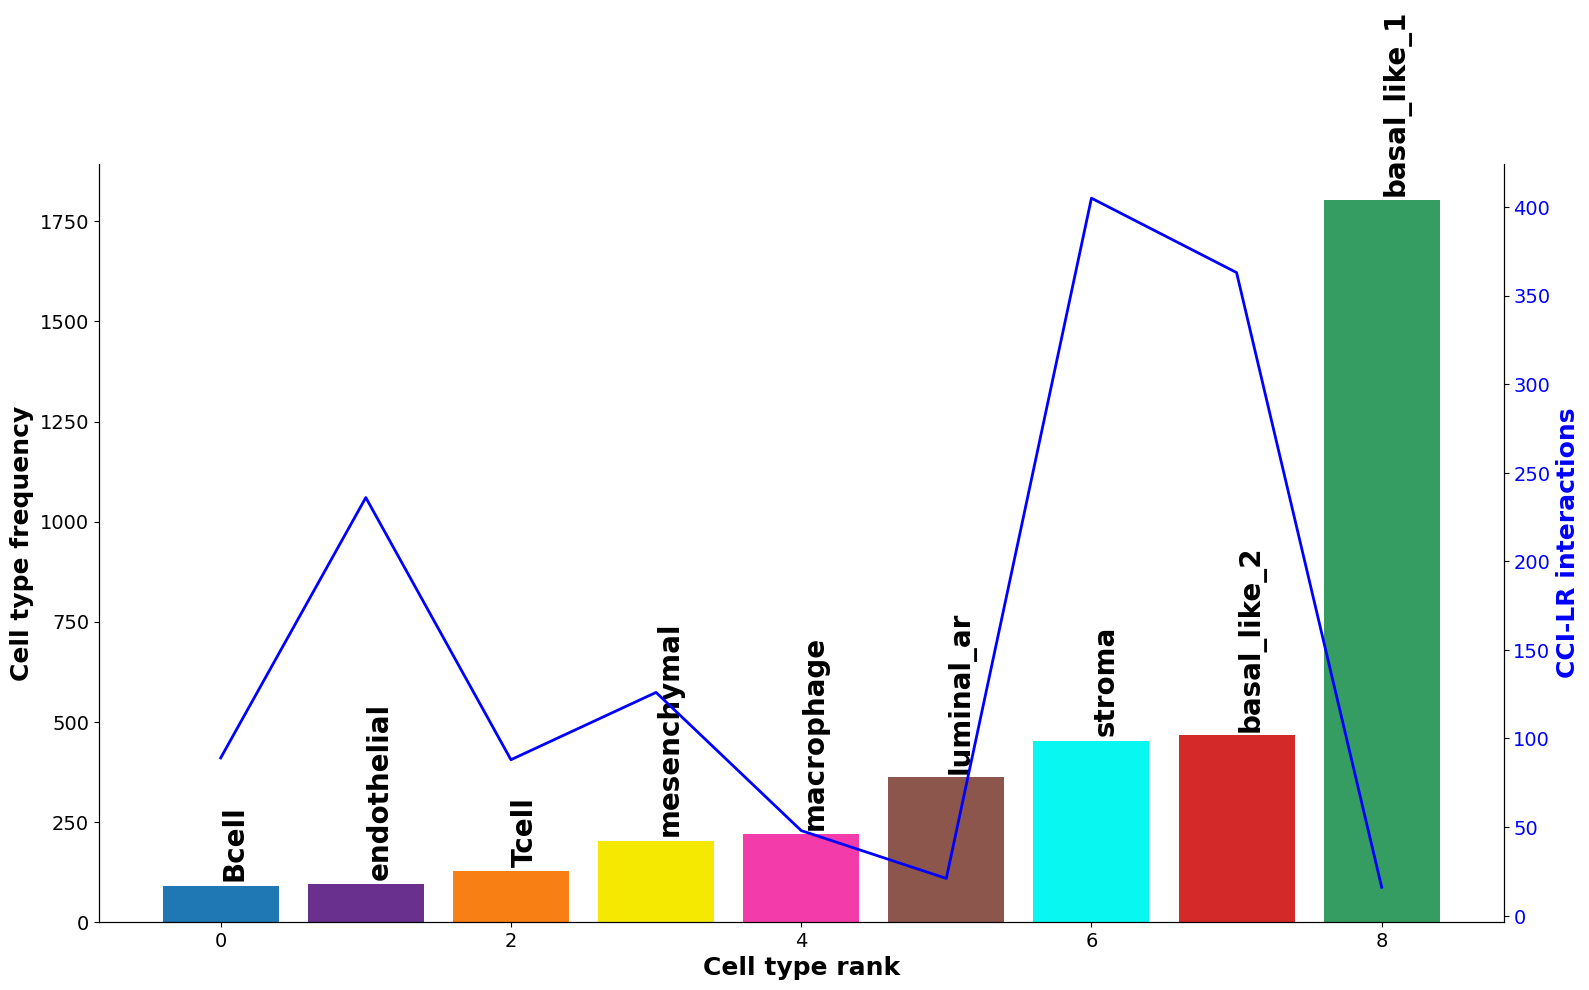

In [ ]:
# 检查相互作用和细胞类型频率相关性
# 如果排列次数足够，下图应该显示很少甚至没有相关性；否则，建议增加上面的 n_perm
st.pl.cci_check(data, 'cell_type')

### 7.5 CCI 可视化

在细胞类型 - 细胞类型预测完成后，我们实施了一系列可视化，以探索不同 LR 对或每个独立细胞对之间的相互作用景观。

如果你更喜欢R的可视化风格，可以保存从 anddata 对象生成这个网络的邻接矩阵，并使用 CellChat 中的可视化函数来进行基于 R 的可视化

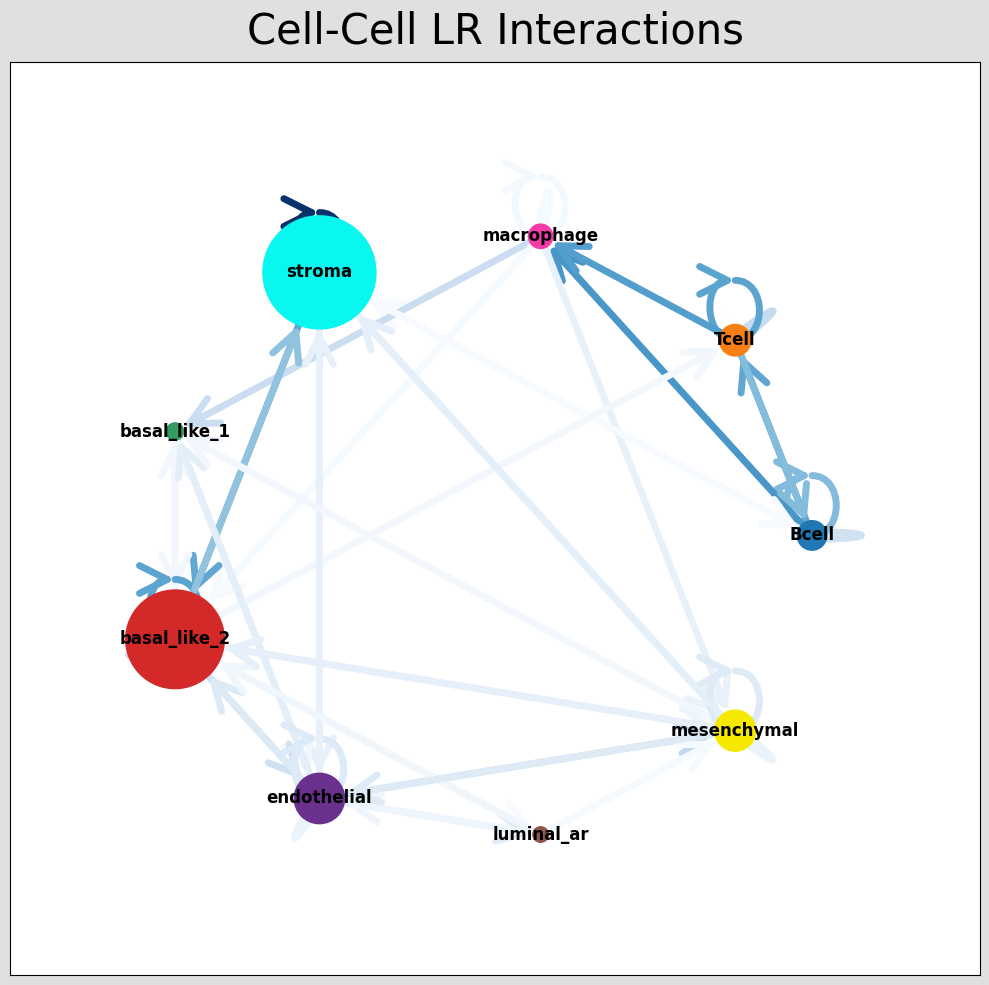

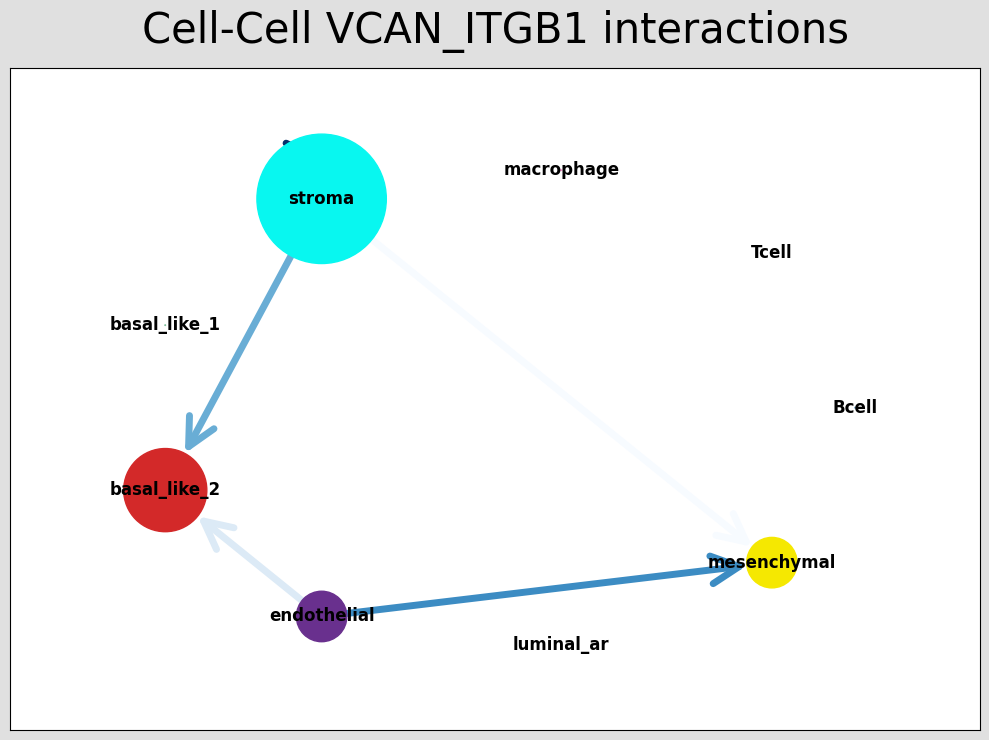

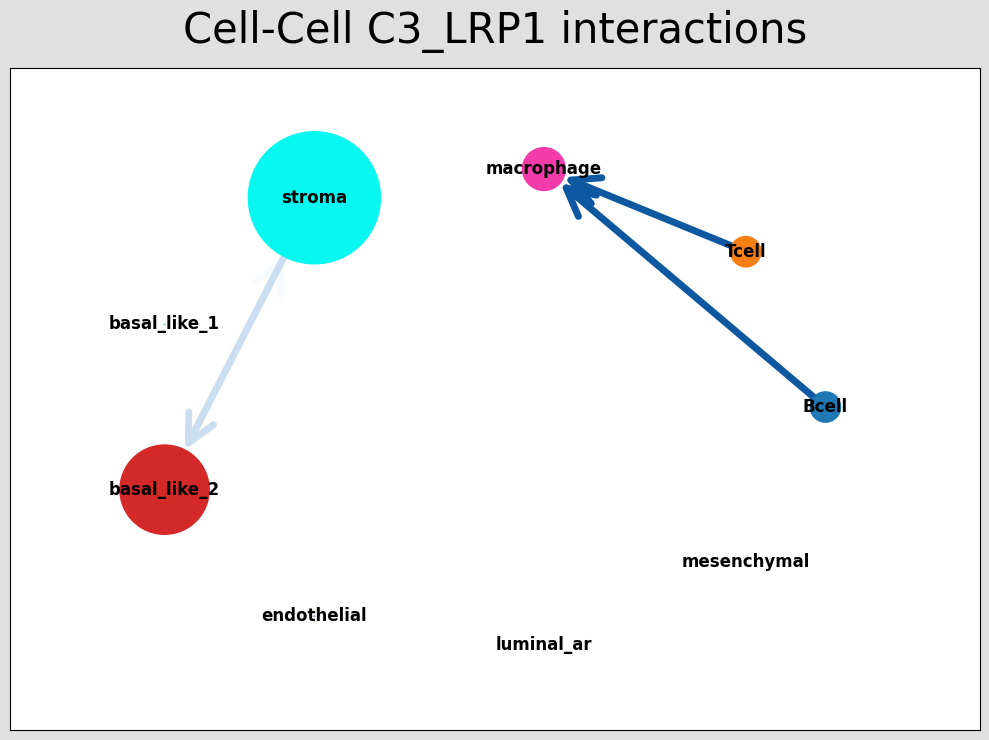

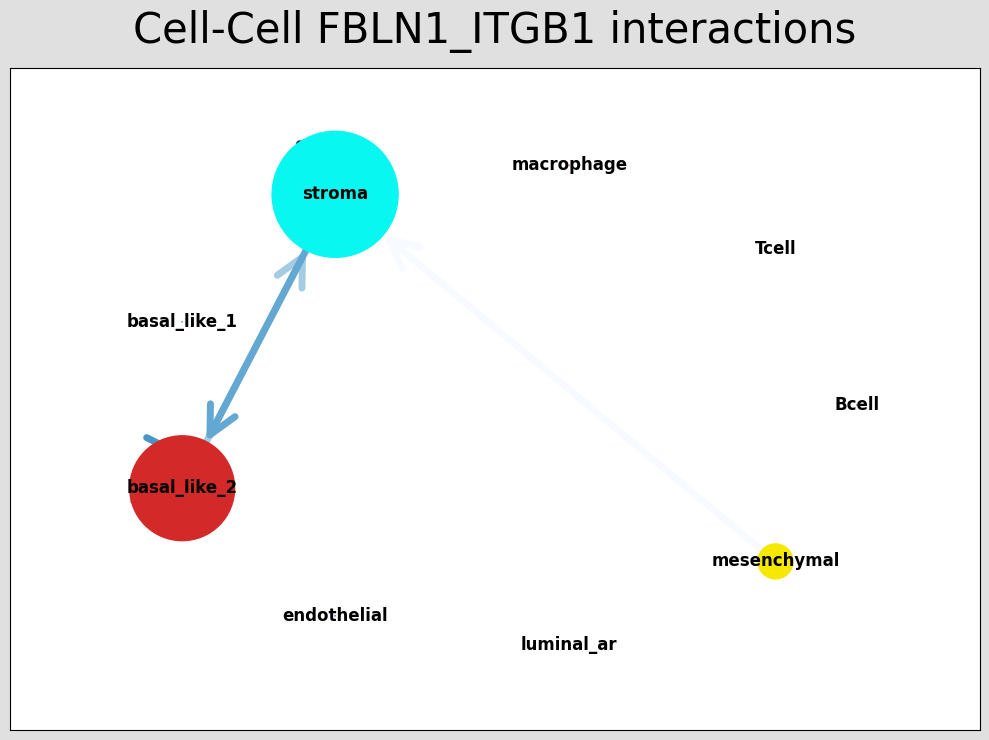

In [ ]:
# 可视化显示所有 LR 对中细胞类型之间的相互作用次数
pos_1 = st.pl.ccinet_plot(data, 'cell_type', return_pos=True)
# [绘制总网络] 调用 st.pl.ccinet_plot 绘制所有 LR 对聚合后的细胞类型间通讯网络
# - data：输入包含 CCI 结果和 cell_type 标签的 AnnData 对象
# - 'cell_type'：指定网络节点基于 AnnData.obs 中的 'cell_type' 标签
# - return_pos=True：**关键**。计算并返回网络节点的位置布局 (pos_1)
# 目的：确保后续的单独 LR 对网络图使用相同的节点位置，以保持一致性

# 只是检查选定的细胞类型相互作用 #
lrs = data.uns['lr_summary'].index.values[0:3]
# [提取 LR 对] 从 lr_summary 摘要表中提取排名最靠前的 3 个 LR 对的名称

for best_lr in lrs[0:3]:
# [循环] 遍历提取出的这 3 个最显著的 LR 对
    st.pl.ccinet_plot(data, 'cell_type', best_lr, min_counts=2,
                      figsize=(10,7.5), pos=pos_1,
                      )
    # [绘制单 LR 网络] 绘制单个 LR 对在不同细胞类型之间的通讯网络
    # - best_lr：指定当前要绘制的 LR 对
    # - min_counts=2：过滤掉通讯次数低于 2 的细胞类型间连接
    # - figsize=(10,7.5)：设置图表尺寸
    # - pos=pos_1：**关键**。使用第一步计算的总网络布局，确保所有子图的细胞类型节点位置固定
    # 目的：直观展示每个关键 LR 对主要在哪些细胞类型之间进行通讯，以及通讯的强度（通常由边的粗细表示）

#### (1) 弦图绘制

和弦图在可视化几种细胞类型之间的相互作用时非常有用。

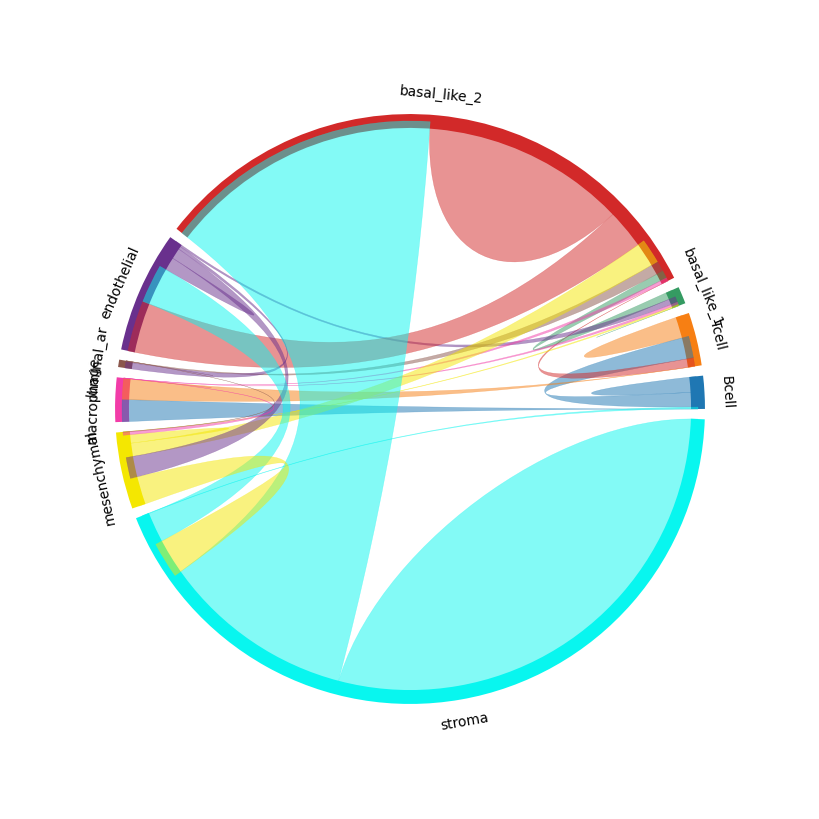

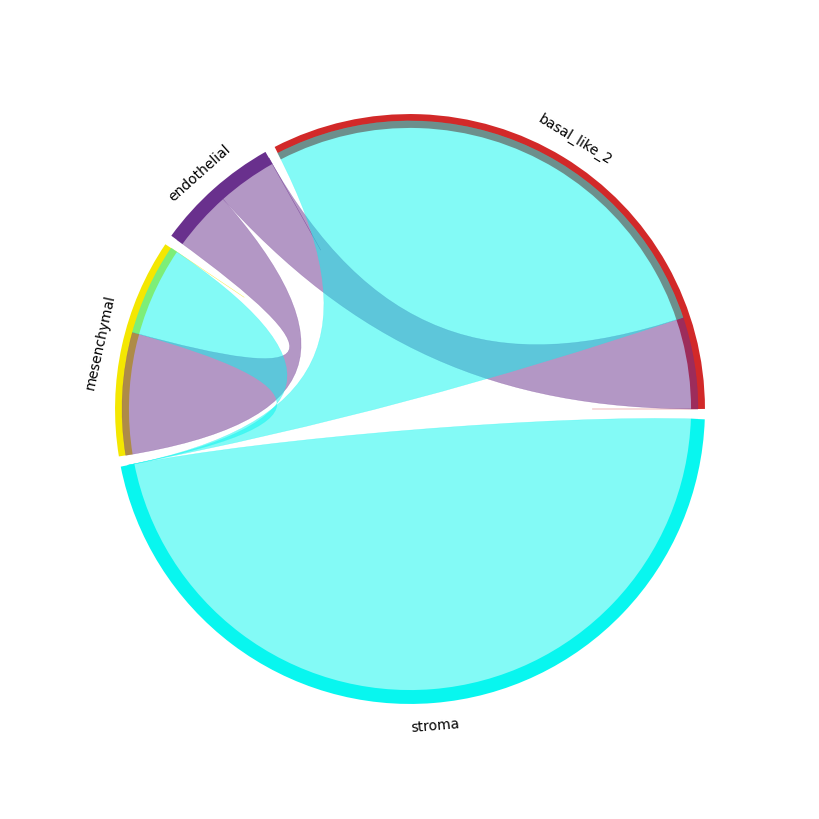

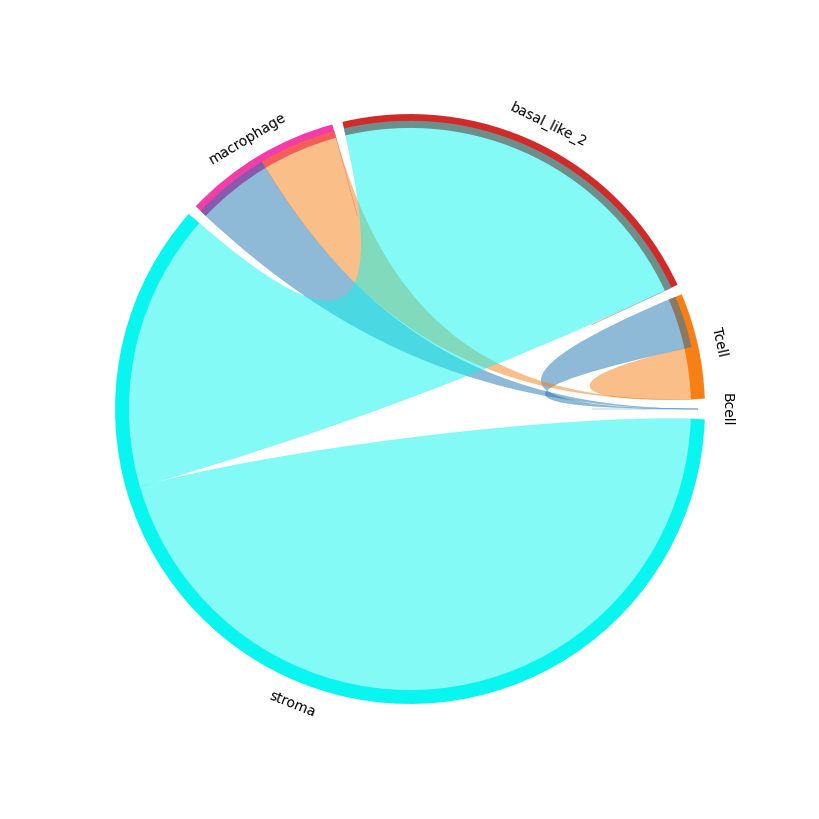

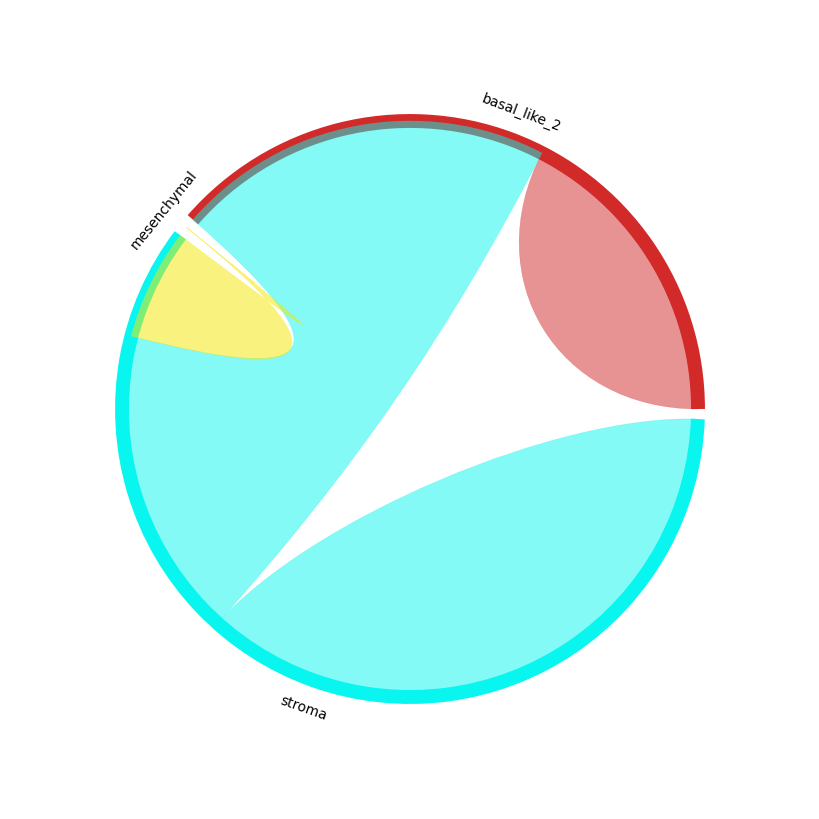

In [ ]:
st.pl.lr_chord_plot(data, 'cell_type')
# [聚合弦图] 绘制所有显著 LR 相互作用聚合后的细胞类型通讯图
# - 'cell_type': 指定网络节点基于 AnnData.obs 中的 'cell_type' 标签
# 目的：展示组织中所有细胞类型之间**总体**的通讯强度和方向。在弦图中，连接的宽度通常代表总通讯强度

for lr in lrs:
# [循环] 遍历预先定义的最显著 LR 对列表 (lrs)
    st.pl.lr_chord_plot(data, 'cell_type', lr)
    # [单个 LR 弦图] 绘制单个 LR 对 (lr) 在不同细胞类型之间的通讯网络
    # - lr: 指定当前要绘制的单个 LR 对名称
    # 目的：聚焦于每个关键 LR 对，直观地展示该特定信号分子主要在哪些**发送方**和**接收方**细胞类型之间发挥作用

#### (2) 热图可视化

一些热图可视化，可以同时可视化多个 LR 对之间的单个细胞类型 - 细胞类型相互作用

<Axes: xlabel='Cell-cell interaction', ylabel='LR-pair'>

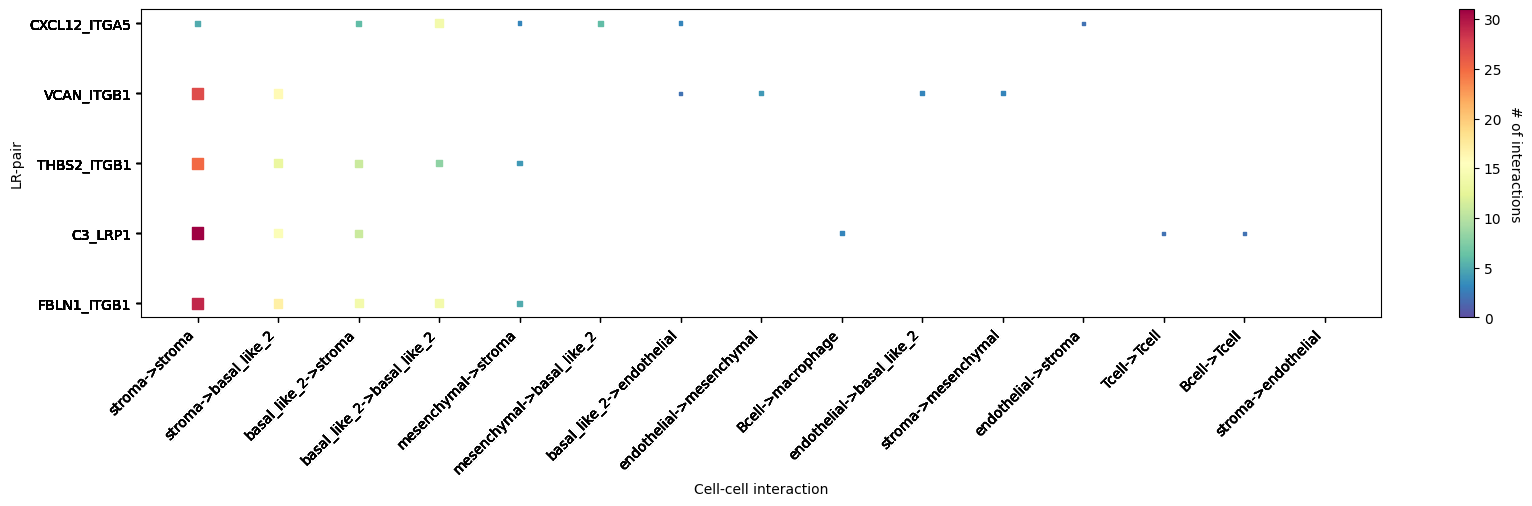

In [ ]:
# 这将自动选择排名靠前相互作用的 CCI 及其各自的 LR #
st.pl.lr_cci_map(data, 
    'cell_type', 
    # [聚类键] 指定 AnnData.obs 中用于定义矩阵行和列的细胞类型标签
    lrs=None, 
    # [LR 对列表] 设置为 None，表示使用所有已筛选出的显著 LR 相互作用对来聚合通讯强度
    min_total=100, 
    # [最小总和] 过滤参数：仅显示总通讯强度（跨所有 LR 对）达到 100 或更高的细胞类型组合
    # 目的：确保只关注通讯最活跃的细胞类型对
    figsize=(20,4)
    # [图表尺寸] 设置图表尺寸为 20x4 英寸，使其宽度大，便于显示细胞类型标签
)
# 作用：生成一个热图（或点图），其行和列是不同的细胞类型。单元格的颜色或大小表示这两个细胞类型之间通过所有显著 LR 对聚合后的通讯强度
# 目的：宏观地识别哪些细胞类型是组织中的主要通讯发送方和接收方

<Axes: xlabel='Cell-cell interaction', ylabel='LR-pair'>

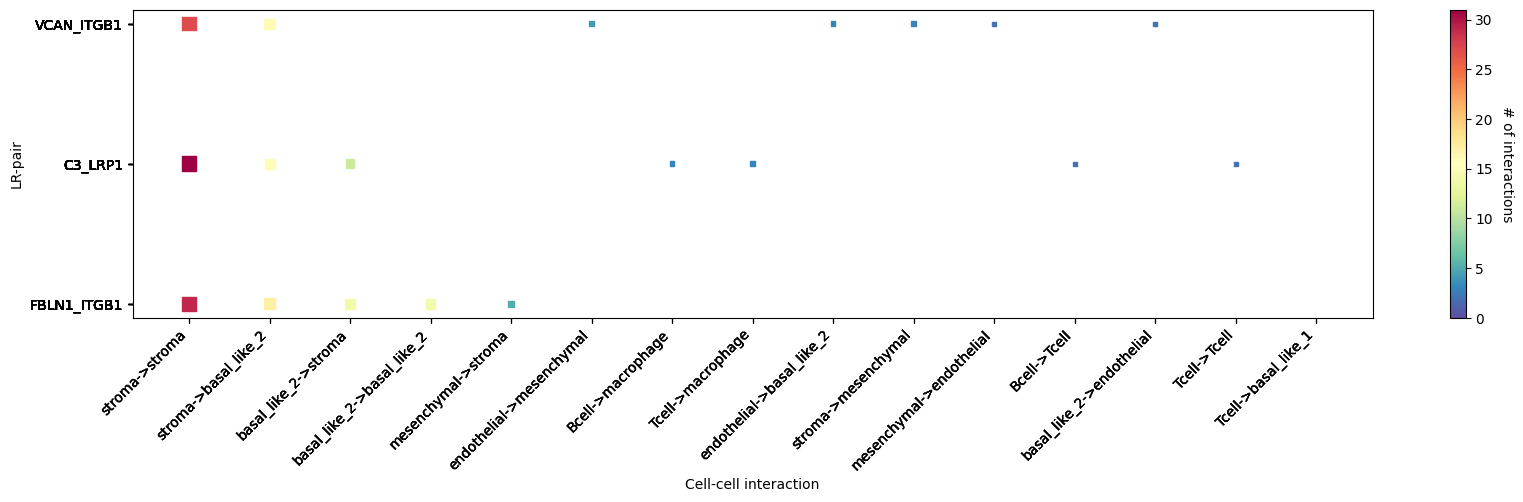

In [21]:
# 也可以选择感兴趣的LR对 #
st.pl.lr_cci_map(data, 'cell_type', lrs=lrs, min_total=100, figsize=(20,4))

相互作用的 是指具有受体细胞类型的斑点表达配体和源细胞类型的斑点在同一邻域表达受体的次数

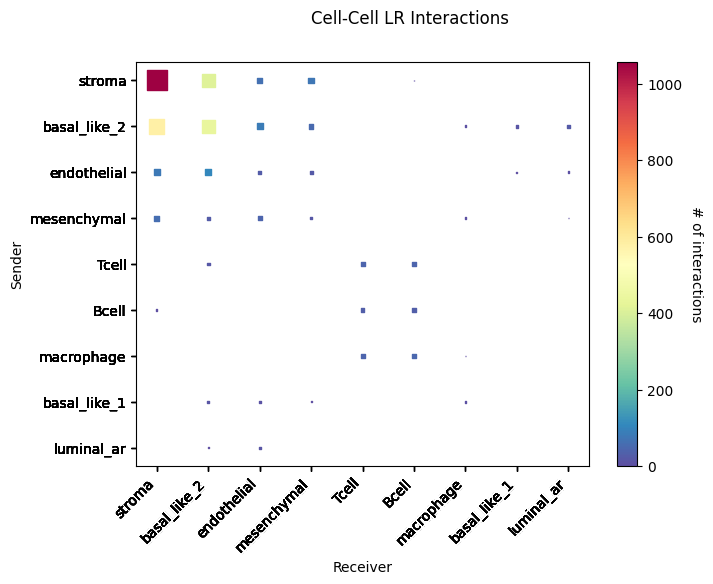

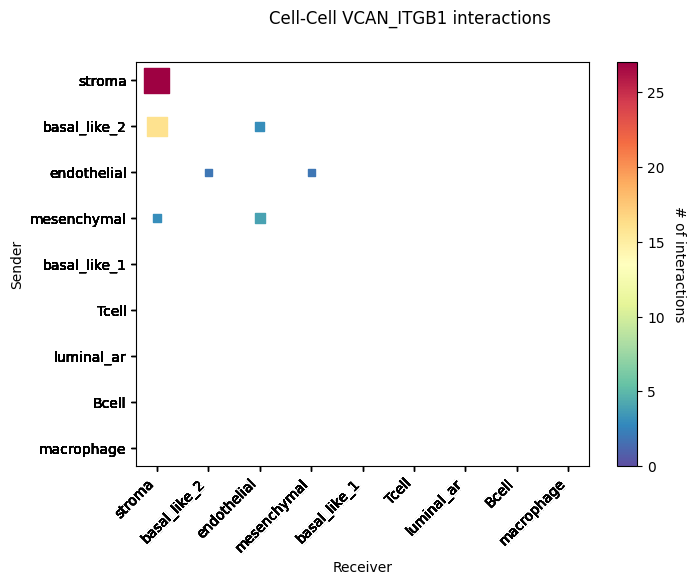

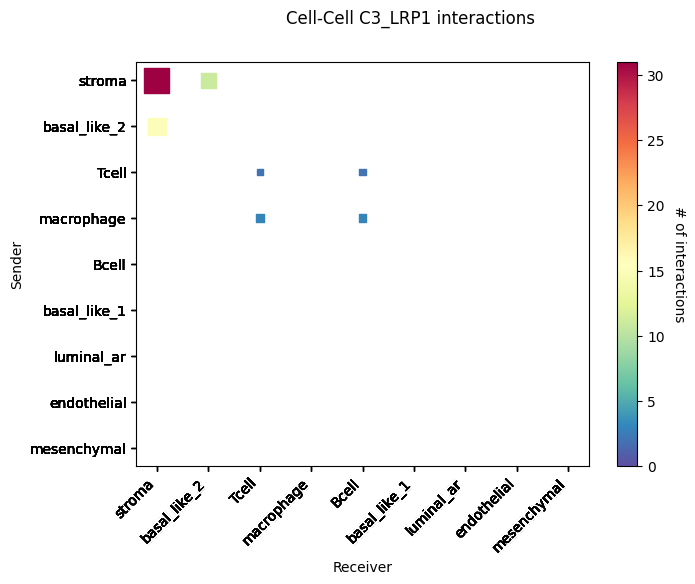

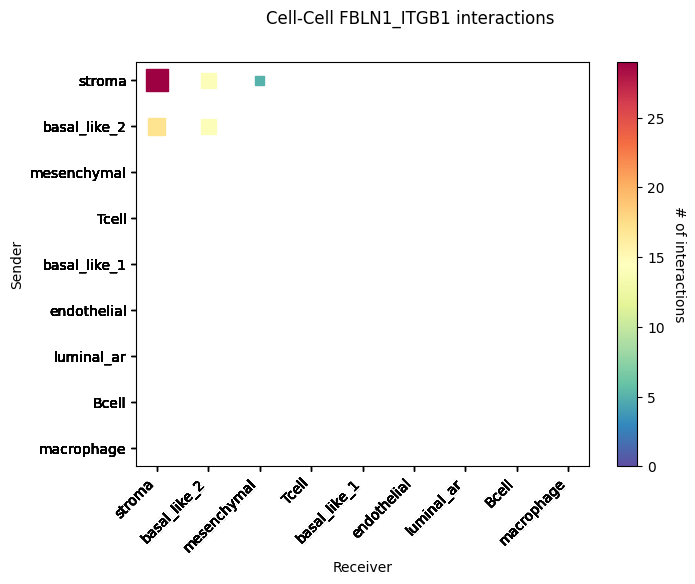

In [ ]:
st.pl.cci_map(data, 'cell_type')
# [聚合 CCI 矩阵] 绘制一个热图，其行和列是不同的细胞类型
# - 'cell_type': 指定网络节点基于 AnnData.obs 中的 'cell_type' 标签
# 作用：展示组织中所有显著 LR 相互作用聚合后，不同细胞类型对之间的总通讯强度

lrs = data.uns['lr_summary'].index.values[0:3]
# [提取 LR 对] 从 lr_summary 摘要表中提取排名最靠前的 3 个 LR 对的名称
for lr in lrs[0:3]:
# [循环] 遍历提取出的这 3 个最显著的 LR 对
    st.pl.cci_map(data, 'cell_type', lr)
    # [单个 CCI 矩阵] 绘制单个 LR 对在不同细胞类型之间的通讯矩阵图
    # - lr: 指定当前要绘制的单个 LR 对名称
    # 作用：聚焦于每个关键 LR 对，直观地展示该特定信号分子主要在哪些**发送方**和**接收方**细胞类型之间进行通讯，以及通讯的强度

### 7.6 结合空间 LR 和 CCI 的可视化

通过将空间 $\text{LR}$ 分析与 $\text{CCI}$ 分析中的显著 $\text{CCI}$ 相结合，我们现在可以可视化这些细胞类型在组织中的相互作用位置。

**核心可视化方法**

建议的方法是绘制细胞类型分布图，并用叠加箭头表示表达配体的 $\text{Spot}$ 和表达受体的 $\text{Spot}$ 之间的通讯流：

1.  **基础图层**：绘制 $\text{Spot}$ 的空间位置，并根据其**细胞类型**进行着色。
2.  **通讯事件**：选择一个**显著的配体-受体 ($\text{LR}$) 对**。
3.  **箭头叠加**：在**被 $\text{CCI}$ 分析标记为显著通讯**的空间邻域内，绘制连接**表达配体 $\text{Spot}$** 到**表达受体 $\text{Spot}$** 的箭头。

这种方法可以在**空间背景下的点状水平**上，通过给定的配体-受体对，清晰地看到不同细胞类型在哪里相互作用：

* **精确空间定位**：识别特定分子通讯在组织中发生的准确区域。
* **分子机制确认**：直接将通讯流与配体和受体的空间表达模式联系起来。
* **细胞类型角色**：直观地看到哪个 $\text{Spot}$（属于哪个细胞类型）扮演发送方，哪个扮演接收方。

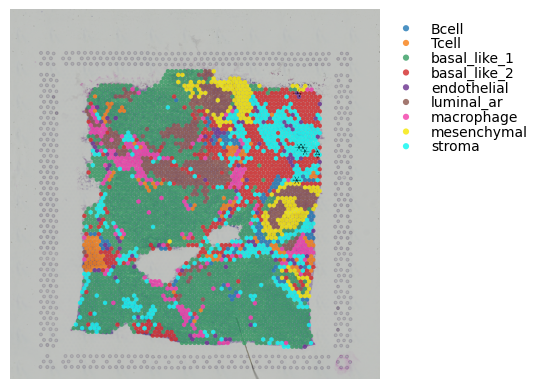

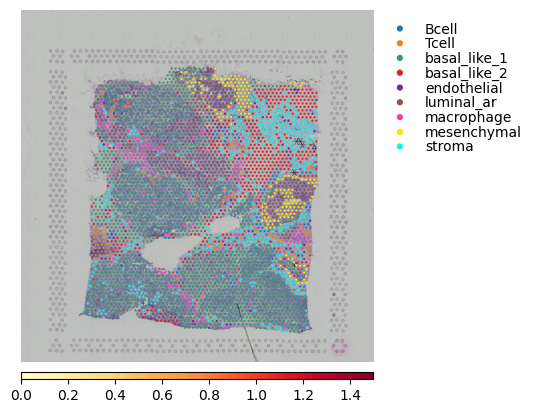

In [ ]:
best_lr = lrs[0]

### 这将用简单的黑色箭头绘制
st.pl.lr_plot(
    data, 
    best_lr, 
    # [目标 LR] 指定要可视化的最显著 LR 对
    outer_size_prop=1, 
    # [外部比例] 设置 Spot 外部圆圈的尺寸比例
    outer_mode=None,
    # [外部模式] Spot 外部圆圈的着色模式，设置为 None，表示不使用
    pt_scale=40, 
    # [点大小] 设置 Spot 的大小比例。
    use_label='cell_type', 
    # [Spot 着色] 根据 AnnData.obs 中的 'cell_type' 标签为 Spot 着色
    show_arrows=True, 
    # [显示箭头] **关键**：设置为 True，绘制 Spot 间的通讯箭头
    show_image=True, 
    # [显示图像] 在 Spot 下方显示组织病理学图像作为背景
    sig_spots=False, 
    # [过滤 Spots] 不基于 Spot 的整体显著性进行过滤
    sig_cci=True, 
    # [过滤 CCI] **关键**：仅绘制显著的细胞-细胞相互作用 CCI 连接的箭头
    arrow_head_width=4,
    # [箭头宽度] 设置箭头头部的宽度
    arrow_width=1, 
    # [箭头线宽] 设置箭头线条的宽度为 1
    cell_alpha=.8
    # [细胞透明度] 设置 Spot 颜色的透明度为 0.8
)
# 作用：生成一张空间图，用黑色箭头（表示通讯方向）将具有显著 LR 相互作用的 Spot 连接起来，Spot 本身按细胞类型着色
### 这将使用箭头连接的点中的平均 LR 表达式为斑点着色
st.pl.lr_plot(
    data, 
    best_lr, 
    # [目标 LR] 指定要可视化的 LR 对
    outer_size_prop=1, 
    outer_mode=None,
    pt_scale=10, 
    # [点大小] 减小 Spot 大小比例（与上图不同）
    use_label='cell_type', 
    show_arrows=True,
    show_image=True, 
    sig_spots=False, 
    sig_cci=True,
    arrow_head_width=4, 
    arrow_width=2,
    arrow_cmap='YlOrRd', 
    # [箭头颜色图] **关键**：使用 'YlOrRd' 颜色图为箭头着色
    arrow_vmax=1.5,
    # [颜色上限] 设置箭头颜色的上限值，用于归一化，防止被异常高值主导
    
)
# 作用：生成第二张空间图。Spot 仍按细胞类型着色，但箭头的颜色强度现在代表了该通讯连接中配体和受体的平均表达水平（或通讯得分），更精细地展示了通讯流的强度

# 8. 作者建议：CCI 可视化技巧与策略

空间背景下的细胞-细胞相互作用 ($\text{CCIs}$) 是高维且信息丰富的。选择正确的**可视化策略**对于有效地传达生物学发现至关重要。

## 8.1 核心可视化组合推荐

根据我们的经验，建议采用以下两步可视化组合：

| 步骤 | 目的 | 推荐内容 |
| :--- | :--- | :--- |
| **第一步：LR 统计数据图** | 确认通讯的**统计稳健性**和**空间强度**分布。 | 绘制感兴趣 $\text{LR}$ 对的 $\text{LR}$ 统计数据图（例如，$-\log_{10}(\text{p\_adjs})$ 和 $\text{lr\_scores}$）。 |
| **第二步：通讯流和细胞类型图** | 定位**通讯事件**发生的细胞类型和确切空间位置。 | 绘制带有**细胞类型信息**和**叠加箭头**的图表。 |

## 8.2 突出显示关键生物学区域

在第二步的**通讯流图**中，最好突出显示感兴趣的区域（如上文中的箭头所指示区域），然后将其放大显示。

| 技巧 | 目的 | 效果 |
| :--- | :--- | :--- |
| **突出显示感兴趣的区域** | 标记预测会发生有趣 $\text{CCI}$ 的**代表性组织区域**。 | 在原始图上，用标记物（如矩形框）圈出目标区域。 |
| **局部放大显示** | 在细节上展示 $\text{CCI}$ 事件的发生模式，避免信息拥挤。 | 放大显示该被标记的感兴趣区域，突出显示预测会发生有趣 $\text{CCI}$ 的 $\text{Spot}$。 |

# 环境信息

In [1]:
import subprocess
subprocess.run(['conda', 'list'])

# packages in environment at /home/chenao/miniconda3/envs/stlearn:
#
# Name                               Version          Build                 Channel
_libgcc_mutex                        0.1              conda_forge           conda-forge
_openmp_mutex                        4.5              2_gnu                 conda-forge
_r-mutex                             1.0.1            anacondar_1           conda-forge
absl-py                              2.3.1            pypi_0                pypi
anndata                              0.11.4           pypi_0                pypi
anyio                                4.10.0           pypi_0                pypi
argon2-cffi                          25.1.0           pypi_0                pypi
argon2-cffi-bindings                 25.1.0           pypi_0                pypi
array-api-compat                     1.12.0           pypi_0                pypi
arrow                                1.3.0            pypi_0                pypi
asttokens       

CompletedProcess(args=['conda', 'list'], returncode=0)

In [2]:
subprocess.run(['pip', 'list'])

Package                           Version
--------------------------------- ---------------
absl-py                           2.3.1
anndata                           0.11.4
anyio                             4.10.0
argon2-cffi                       25.1.0
argon2-cffi-bindings              25.1.0
array-api-compat                  1.12.0
arrow                             1.3.0
asttokens                         3.0.0
astunparse                        1.6.3
async-lru                         2.0.5
attrs                             25.3.0
babel                             2.17.0
beautifulsoup4                    4.13.5
bleach                            6.2.0
bokeh                             3.7.3
cachetools                        5.5.2
certifi                           2025.8.3
cffi                              1.17.1
charset-normalizer                3.4.3
click                             8.2.1
comm                              0.2.3
contourpy                         1.3.2
cycler          

CompletedProcess(args=['pip', 'list'], returncode=0)

# 单细胞教程全收录
[B站视频](https://www.bilibili.com/video/BV1S44y1b76Z/):先看一遍视频再去看推送操作，建议至少**看三遍**  
以下的资料都可以在这里订阅：
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Seurat V5更新版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519711&idx=1&sn=d25d4f5daf609bda8367f16db676ecf3&chksm=9b3cf48fac4b7d99e65eba6d4c66c63e40b1d187fa1d9e6449d6cd07d5dec5127cff54886f93&scene=21#wechat_redirect)    
[scRNA-Seq学习手册Python版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504877&idx=2&sn=2b56a9cfa19fcc918ee6c2ed88fed017&chksm=9b3caabdac4b23ab6e28425a4a5eb4d40ee3612e51f84f5d1e53ac91bef93f717e9e754398e3&scene=21#wechat_redirect)    
 
## 单细胞测序基础数据分析**保姆级教程**，代码部分整理在往期推送之中：
[手把手教你做单细胞测序数据分析（一）——绪论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499776&idx=2&sn=7fc250d94ed88cfd5e2224f071bb1742&chksm=9b3cb950ac4b30467a082527547b91aec15b7d1f40d44e362894aedeb6a99e014518fa5e4743&token=767842863&lang=zh_CN#rd)  
[手把手教你做单细胞测序数据分析（二）——各类数据结构与读取方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499795&idx=2&sn=68e6298eb43633c71939c146d90230ff&chksm=9b3cb943ac4b3055e09739d77e037d679f3d9ec68780d1aa8c592f806fcc8d2322eaee78752d&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（三）——单样本分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500010&idx=2&sn=2f9fd1b0101d579bcd250fdc24e98bfc&chksm=9b3cb9baac4b30ac6f0ce28a6dd10470e73d1e1d6defece5636939a32a6db9b2cce0ff8688eb&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（四）——多样本整合](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（五）——细胞类型注释](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（六）——组间差异分析及可视化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500117&idx=2&sn=cef0b0abec6d73a8c2615980ef68aec1&chksm=9b3cb805ac4b3113fdc820b9c9667f9554b2e39f90c45b5806021a415698b0a5141c521c64dc&scene=178&cur_album_id=2923694853375688706#rd)  
[手把手教你做单细胞测序数据分析（七）——基因集富集分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500357&idx=2&sn=40034079b771c478b482e849ed4b216c&chksm=9b3cbb15ac4b3203d517ff71073ab0520fe144bc108b7a26f6b17e88fb63a78c5777946618e3&scene=178&cur_album_id=2923694853375688706#rd)  
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)    
[Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)
  
## 单细胞图片改造计划
[改造单细胞降维图| 1.DimPlot的探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496162&idx=1&sn=598c2920f7cc0697ee5a1fa6cadaee04&chksm=9b3c88b2ac4b01a415feeebbbec6c4891319439dc8dcdafd33cca7a1222e5adc723ae9d3a73d&scene=21#wechat_redirect)  
[改造单细胞降维图| 2.ggplot2中的DIY](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496239&idx=1&sn=1fe6fd4a7fb88ecc0456b4f5710cb5d6&chksm=9b3c8b7fac4b0269e0abeab951ad6ae0ddd1464dd9d1867280eeb9755fda5ba8f5237d88a7a6&scene=21#wechat_redirect)  
[改造单细胞降维图| 3.3D降维图与动图绘制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498080&idx=2&sn=a9bcf65e3ae34ba201e8d49ee33c0728&chksm=9b3c8030ac4b0926c3f059a9a5d23f1bcdbcaf8e5a562eba2b7e3bec3396c44573269bd08e7b&scene=21&cur_album_id=2707677276481814529#wechat_redirect)  
[改造单细胞降维图| 4.一些造好的轮子](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498191&idx=1&sn=952312a6b26232d460bf787cc276543f&chksm=9b3c809fac4b098972c8c1dd83b9f954a38fe5b5f6bc7e295f3f3a7ba6c4c3d32951679ac24d&scene=21#wechat_redirect)  
[沉浸式统计细胞比例](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503971&idx=2&sn=7dafb1e743ebbb95e488d8d1b7024448&chksm=9b3ca933ac4b2025f922a325ec6893e93613f130ff1d4fd609e2d7274f7f1fdb5134092e28ad&scene=21#wechat_redirect)  
[改造单细胞FeaturePlot](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504616&idx=1&sn=f7b4a0e6b25d224380cd803e3463a3e4&chksm=9b3cabb8ac4b22aeb65e0d6ec32a1f8674dcf907da078ccb3b61e06c4aa035864ebec092f571&scene=21#wechat_redirect)  
[VlnPlot用法及ggplot复现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504768&idx=1&sn=4fc5eb47037d3a80178e32975488d70b&chksm=9b3caad0ac4b23c61147cfb0f46ecd846568f37ce89c963eb5f069d3e89a8ba285897726bb3d&scene=21#wechat_redirect)  
[VlnPlot的ggplot改造](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504843&idx=1&sn=b795a3e36ae092d8f87abb5a87187828&chksm=9b3caa9bac4b238dd33e905c33924b58aa4ff14e83abbf08046fba7fe765ecb0204163cb6acf&scene=21#wechat_redirect)  
[改造单细胞DotPlot](https://mp.weixin.qq.com/s/GPp-QYwT6jOjFfeZjs9hZg)  
[改造单细胞DoHeatmap](https://mp.weixin.qq.com/s/V_JhpBOy1wG6U-uQsj8CPQ)   

## 3、SCENIC转录因子分析：
[1.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500098&idx=1&sn=8c31241bd259e303a6ac3c9740f298d9&chksm=9b3cb812ac4b31046fd298c8ee5f0bc0de445df62b234bd934c34ca655e61de3da54d81e2053&scene=21#wechat_redirect)  
[2.学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500439&idx=1&sn=d6b4874a8352f5b7a4165629c03058ce&chksm=9b3cbbc7ac4b32d158fd3c5c2f155c54c892d40eaae3718409936fc319f69705da32badf79d6&scene=21#wechat_redirect)  
[3.软件安装与数据准备](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500631&idx=1&sn=5d73db4dcc74b66de07dee9db910bb83&chksm=9b3cba07ac4b3311d1820bb305778aea707294f19fd6ff2631cd003da80bdcff8f8bc8ed34de&scene=21#wechat_redirect)  
[4.精简版流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501260&idx=1&sn=f1e2a165599e753e2959aad7c8a298cb&chksm=9b3cbc9cac4b358a9499654a2f95fa9010309ee4f408ef8b1f31ceb1a0f263ce22e8b511c430&scene=21#wechat_redirect)  
[5.step1+step2构建共表达网络与regulon](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501692&idx=1&sn=3f7e263a93942ad03faa1ba5f8694ec4&chksm=9b3cbe2cac4b373af9db74a50ffb08a9b8a3b958fc6385c937385f0f7323bc935cdb0fe5275c&scene=21#wechat_redirect)  
[6.Step3 利用AUCell对Regulon评分](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501989&idx=1&sn=2700bf779d7d261a4d751d1635fdce2c&chksm=9b3cb1f5ac4b38e3014476242fe956cf510cc45b9f4cef86070af8094fd5f884f9d5c3a3363f&scene=21#wechat_redirect)  
[7.Step4 二元矩阵的计算与可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503995&idx=1&sn=26c7e9ec56af434e62b02853cfe667d6&chksm=9b3ca92bac4b203d7986645ab5a3fb574f44185c7ced8bd47957fa237d436a95bfa2579d052a&scene=21#wechat_redirect)  
[8.Step5 regulon聚类、分群、降维](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504024&idx=1&sn=143c0ec4d94b8fca0a4a47d3dc24415b&chksm=9b3ca9c8ac4b20de70a87acb2d3f810b0e1497071b1c6f14f1882a6d844fff016e9ba5581eb3&scene=21#wechat_redirect)  
[9.下游探索](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505276&idx=1&sn=949c753feb85d5877121433caaa33013&chksm=9b3cac2cac4b253affb587a937d3f5e0576851a4f4e1570cb7510a594d155873961bbd91758d&scene=21#wechat_redirect)  
[SCENIC转录因子调控网络图](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520750&idx=1&sn=496bead1531a7eddd5c286030d350745&chksm=9b3ce8beac4b61a8589a1f8a66bd0571e09c0646655b6d805348bf6f4a0c7b52851615c22868&scene=21#wechat_redirect)  
  
## 上游**fastq**文件处理：
[单细胞分析的最上游——处理Fastq文件：cellranger](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484923&idx=1&sn=b5876af14fbee68d1e9db4b0f70cd1c8&chksm=9b3f7cabac48f5bdb3aac7d20201d89121a83720b41a10017564fedbb8c4a13df0da92daffd7&scene=21#wechat_redirect)  
[单细胞分析的最上游——处理Fastq文件：dropseqRunner](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484937&idx=1&sn=4fe1fa518202bdaf462bb93a2614ed32&chksm=9b3f7f59ac48f64fafaf34bac2c80f06d3a86b6a84ccf12566c7eac25bb71c7edd3d74004cf7&scene=21#wechat_redirect)    
[Cellranger报错：Unable to distinguish between](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504739&idx=2&sn=e4e6ad0559b9b6a703d6ab37c2a8fdb0&chksm=9b3caa33ac4b23257424184bda44dd600ad98bc0dfdfa90ab0e3ebaf208e598b0b710fbafa4b&scene=21#wechat_redirect)  
[BD Rhapsody平台单细胞转录组定量流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506542&idx=1&sn=99cf7af7fc0d56b0d6fe7ea3596df2b6&chksm=9b3ca33eac4b2a28e6682a7cf0b2091a387a06ecf89ee10737cf2194286ec0bba472ef1c2b90&scene=21#wechat_redirect)  
[BD Rhapsody定量输出文件读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519706&idx=1&sn=9d084bd8edf6ab4d9184672e5a4a2722&chksm=9b3cf48aac4b7d9c16ef85de7a5f33e65552bbba5d11d2170237063cf754fe9ff376647d3bd7&scene=21#wechat_redirect)  
  
## **细胞通讯**
[跳转B站，连播更方便](https://www.bilibili.com/video/BV1Ab4y1W7qx?p=1)  
**往期推送**  
[《细胞通讯》CellChat学习手册](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501735&idx=2&sn=35fc792961507f4ae1cbae3a2882fba6&chksm=9b3cbef7ac4b37e1417d4108c8bd378c68c3907431ddfc52ad37c916e85649bb450d761a8e19&scene=21#wechat_redirect)  
[《细胞通讯》1.概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501282&idx=2&sn=cd37ea80e0b92f5bfbc98ea286e363da&chksm=9b3cbcb2ac4b35a4258d21fe003374795619fc2356376ebbe4ff640233f4b4c6e3e3ead41370&scene=21#wechat_redirect)  
[《细胞通讯》2.1CellChat基础分析教程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501296&idx=2&sn=fb3e252d95ee8b50cd446e71335b1aa0&chksm=9b3cbca0ac4b35b621b4f51d2c3a130f00461faeeff067396222c2fc2eeb53f3544664d7d9bc&scene=21#wechat_redirect)  
[《细胞通讯》2.2CellChat多组别分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501523&idx=2&sn=6fa803f256c2e0b945f93ae7d8245f50&chksm=9b3cbf83ac4b3695b587e9817840f419104c8680f5ef08ee39aa149b79852f48b179f68e3397&scene=21#wechat_redirect)    
[CellChat空转细胞通讯合辑](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512011&idx=1&sn=fbd41832c5995d79fead016931d3bfbd&chksm=9b3cd69bac4b5f8d16e7d8b8eeb5490e4938daf68902b06a8d60e25f150ec4ec459796f3aaac&scene=21#wechat_redirect)  
[SeekSpace细胞通讯分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511890&idx=1&sn=3457b875cd00b4433f50a39a45e1cb8a&chksm=9b3cd602ac4b5f144ad982dfbdf583b56d1bfb768e4e5f2cc9e5424af6e014e752835fadc8a6&scene=21#wechat_redirect)  
                              
## **拟时序分析**
[B站连续播放起来比较方便](https://www.bilibili.com/video/BV1br4y1x7Hf?p=1)  
**往期推送**  
[1.概论](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486553&idx=1&sn=b689ec962a17ca1a1ada29ae8ff8c019&chksm=9b3f7509ac48fc1f0f81e288de8f15c86548215a1cd9d5c740dc63f2421371d13890398ab1df&scene=21#wechat_redirect)  
[2.monocle概论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487001&idx=1&sn=329129e75f703e3f332e76af9c66871e&chksm=9b3f7749ac48fe5f081248c2a48c56685e3915015036c73f8f67ec3e6acc246ddf815daedb22&scene=21#wechat_redirect)  
[3.monocle2实操：精简版](https://mp.weixin.qq.com/s/k-1Jdc0J9EXb2jfwo7935w)    
[4.monocle2实操：完整版](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497730&idx=2&sn=930dc0e276219d70c937e943119388ff&chksm=9b3c8152ac4b08446d457cef3ede4a4a17c0ebacaec0c36efe7d7c8706fb4a3d62222d702ee5&scene=178&cur_album_id=2820794880947159043#rd)  
[5.初识monocle3](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489044&idx=1&sn=061dbfc34d200b73a8227d0bb28a1d27&chksm=9b3f6f44ac48e65251f7e5ecce84637c05d50ecb92769e8386f221f8e7b9bfeb719232def863&scene=21#wechat_redirect)  
[6.monocle3的降维、分群、聚类](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489494&idx=1&sn=44f0a44857c12fcf9a1ab84e4f2cbebf&chksm=9b3f6e86ac48e79026321de2fdca81a139d104d655884ffe87a68e0a1551ddffa5af7919d19e&scene=21#wechat_redirect)  
[7.monocle3的拟时序分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490418&idx=1&sn=18ae0b6139fe1a2436dcf6cc47850297&chksm=9b3f6222ac48eb3450de0b02a34eb5fff2db89ab8f155460d554cbb23be0cd27fd349079e7b2&scene=21#wechat_redirect)  
[解决monocle2的orderCells报错的两种方法](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491083&idx=1&sn=c5697ab024193cb6595d27e4f4d3bfaf&chksm=9b3f675bac48ee4d7244d9819e14fe210f7e42e40fc7a6a8df7b95bfd92f06334d60d226cb93&token=333450324&lang=zh_CN#rd)  
[一文搞定拟时序分析的下游可视化探索](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497634&idx=1&sn=64872660e8ce80ff08c6c0745c2b241b&chksm=9b3c8ef2ac4b07e4a2ef03870c91fdc1c3ded245dcecd5a2049841cb7e9749bd1cd0852133f1&scene=178&cur_album_id=2820794880947159043#rd)  
  
## 单细胞拷贝数变异
[单细胞拷贝数变异学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522733&idx=1&sn=4e3a0707fd8f83b5ad9377bc91ee8e53&scene=21#wechat_redirect)

## scATAC
[scATAC分析学习手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521636&idx=1&sn=208907010f3f7412c1c91343d7dfb0d3&scene=21#wechat_redirect)  
[一文了解单细胞染色质及常见分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522998&idx=1&sn=843d378d3b679951ad3c8e5da7c32d87&scene=21#wechat_redirect)  
[一文了解染色质可及性和表观基因组调控](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510114&idx=1&sn=f7e8b1df1804a6bba0d79b1ffec2467c&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&scene=21#wechat_redirect)  

## **scFAST系列**
[01.绪论](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503875&idx=1&sn=2b5ca0c57e17e51abb52adfe199c5736&chksm=9b3ca953ac4b20450f643b94bcfc95aa2b04ded197ce93e455a281901d7ccba099b48cfd03d9&scene=21#wechat_redirect)  
[02.单细胞分析准备工作](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504023&idx=1&sn=4091a22e853242b4aae7a7d3b4008f5c&chksm=9b3ca9c7ac4b20d1bb0389fad5fe85a3c4cf49179747fe97dffaab1087b7d2793668d9f63aa4&scene=21#wechat_redirect)  
[03.fast模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504044&idx=1&sn=d37991280217dcc29280efa344f856bb&chksm=9b3ca9fcac4b20eab124ccd4ba6ad3f5eee640df314e7d8fec0225035f06178e3a51dbe2033f&scene=21#wechat_redirect)  
[04.Seurat分析及可视化](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504435&idx=1&sn=c6a6f7ca00684601f3cda49e53be5339&chksm=9b3cab63ac4b2275d993bbaa64c71652685065fa377be57319fc6a5c47eb958b3644c7459cd5&scene=21#wechat_redirect)  
[05.mut模块](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504878&idx=1&sn=2c5d9fc694eaf3e264c38b0691cd3a43&chksm=9b3caabeac4b23a87d201009137572c02ba1ea0dd747bcd8b8c02878b45917b6e235551c41cb&scene=21#wechat_redirect)  
[一文学会scFAST-seq数据分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505213&idx=1&sn=5f4ed0587dd96149d127a98d36f721f0&chksm=9b3cac6dac4b257bbc00c4647382d27883139bf06ab3071947bf1cccde8d1d501006dabab5f1&scene=21#wechat_redirect)  
  
## 其他单细胞相关**技术贴**:
[应审稿人要求| pseudo bulk差异分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521437&idx=1&sn=d47b48170f7189b8fb74b2316d0c4898&chksm=9b3cedcdac4b64db43487176203e52e53fe08e01ce819a1615fa1e2f9f8d513bbd4efdee5558&scene=21#wechat_redirect)  
[genesorteR——比FindAllMarkers快一百倍！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521266&idx=1&sn=2a74f282222b694f51362445e65c85a6&chksm=9b3ceaa2ac4b63b4a721d1134317af5ee1c9fbe844383a1f404249748e506b674ea26e66d0d2&scene=21#wechat_redirect)  
[单细胞必修课——Seurat流程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247512220&idx=1&sn=c71bc3f1ef007eb29be8b3b4ec10f0af&chksm=9b3cc9ccac4b40da749d2388dc2d885239a1e4f6ea0989f36b031c7253ce103b061e2605ad8c&scene=21#wechat_redirect)  
[scRNA-Seq双细胞过滤手册](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511622&idx=1&sn=60b35668e569267bab14ec8fbba8bd74&chksm=9b3cd716ac4b5e00122eac47f55085198040a4a0e97c56895bbc39f3a9f1a1eb4eba27048a8f&scene=21#wechat_redirect)   
[scRNA-Seq学习手册Seurat V4修订版](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510380&idx=1&sn=0eb2b0c519ef1dc25ee8821b736a0fde&chksm=9b3cd03cac4b592ad93149fb4847e6ba3dd03ab69e1ca594ddc64d323fb7496775789cae245d&scene=21#wechat_redirect)  
[快速上手Seurat V5](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509880&idx=1&sn=3b7cd169ccfe688d10cb1ca70dc91e91&chksm=9b3cde28ac4b573ec6d5f4bceafa4294c0e9a001b7d0c0b64f274a9978b1438eeccc747ca0c0&scene=21#wechat_redirect)  
[单细胞Figure 1常见图表(视频教程)](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247509260&idx=1&sn=9ff90a428c3f22d43a31ec864e2d8a94&chksm=9b3cdc5cac4b554a2f7cb2a6368f7df9a9a3f6e406eb070663f53d81841a76e188c0b50727de&scene=21#wechat_redirect)  
[SCTransform与ScaleData](https://mp.weixin.qq.com/s/6jwfDa22EUgo2wYpmxCCFg)  
[细胞的数量由誰决定？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484056&idx=1&sn=4967a054f5241ff3a1bd4a6fe9a502b1&chksm=9b3f7bc8ac48f2deca3141461be035deb8658be184d78597af28f8ba2092d12f020768275248&scene=21#wechat_redirect)  
[单细胞中应该如何做GSVA？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484701&idx=1&sn=ad90680f252d092a2e21f349c8f32cab&chksm=9b3f7c4dac48f55bf1d11337406ab0e1295e8e1731dbac0715eedc99d11beff7f380e42dd49b&scene=21#wechat_redirect)  
[答读者问（三）：单细胞测序前景](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484280&idx=2&sn=844af02070012a1c2681880596ba51a2&chksm=9b3f7a28ac48f33e95eb906121be8953410ca4c572c8035cb801609a56caf9dcff57fa989602&scene=21#wechat_redirect)  
[答读者问（四）：如何分析细胞亚群](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247484316&idx=2&sn=e8d02fddc80d1137bb64c55541f1651d&chksm=9b3f7accac48f3da7df7fcad9c996291bc66967c04d16dde92ed391c56e610a7298ac8fb7dbb&scene=21#wechat_redirect)  
[答读者问（八）：为什么Read10X也会报错?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485012&idx=1&sn=6007c8d7cb2a236dd7240a678dac0391&chksm=9b3f7f04ac48f612f811c1df9e9450dc8112d343e4bf245be5149c2e2a073d3e339cd0e3ff61&scene=21#wechat_redirect)  
[答读者问（十）整合后的表达矩阵，如何拆分出分组信息？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485134&idx=1&sn=13f5f8c47d8af2beeca4e103a5f5e26d&chksm=9b3f7f9eac48f688b454a1062ee4e41f7072ac9d58e5466fa7ed4bb05018adbfe167bb3a445a&scene=21#wechat_redirect)  
[答读者问（十一）如何一次性读取一个目录下的cellranger输出文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485145&idx=1&sn=402cb28c16aba0dc647037c9b7aba8f7&chksm=9b3f7f89ac48f69fe27cd427df3eff2e88c240bf20dfe92d8b522eecd7302d132d880bf29047&scene=21#wechat_redirect)  
[给你安排一个懂生信的工具人（十）：不学编程 零代码完成单细胞测序数据分析：Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485730&idx=1&sn=42b9b35026bec5359ac34750dea3bf44&chksm=9b3f7072ac48f964970f673a86e27ecd453a80b953168dc110e0ea6bfa4110eeed3350c9601a&scene=21#wechat_redirect)  
[什么？不做单细胞也能分析细胞类群和免疫浸润？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485798&idx=1&sn=c849bc7a0093af92fc99e13b55842bb2&chksm=9b3f7036ac48f92048d726b38f2dd978d0b0cce779c1a4090aa4da5cb2df3ad30a5c5dbed27e&scene=21#wechat_redirect)  
[答读者问 （十三）查看Seurat对象时的ERROR：type='text'](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485859&idx=1&sn=a014c4cb6034551e57c70820c7781e49&chksm=9b3f70f3ac48f9e52620e3ff197eb98e58836e8bb6baad634387a521fdda1e4a194356517c73&scene=21#wechat_redirect)  
[各类单细胞对象（数据格式）转换大全（一）](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485925&idx=1&sn=14e08440200f0f5cb4dcc2dc615efeb8&chksm=9b3f70b5ac48f9a37a43cc2a8b2a5e485a3f84b4ef87949dfe99056bc6301b110e80800f6bb1&scene=21#wechat_redirect)    
[单细胞对象(数据格式)转换大全|2. h5ad转Seuratobj](https://mp.weixin.qq.com/s/iYz4ZsD-oJ2ZJsZpbGKRsg)   
[批量整理好GEO中下载的单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486045&idx=1&sn=0b6874bcffc8abafb505cabce4c4fc0e&chksm=9b3f730dac48fa1b140ef01c07a7749e69df4fa7d2056deeed0673c668b6246724cd85741125&scene=21#wechat_redirect)  
[答读者问 （十四）Seurat中分类变量处理技巧](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486134&idx=1&sn=e581b8ac20bbc968aeef3f9cf56f3a0f&chksm=9b3f73e6ac48faf0f1c81752b0190abc617eb720a71806950e7851c7d19b7e3e092aa97bd005&scene=21#wechat_redirect)  
[答读者问 （十五）稀疏矩阵转matrix, as.matrix函数是下下策](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247486259&idx=1&sn=97de5c9e15e48cb62c8a680376a4ee0d&chksm=9b3f7263ac48fb75a91b40416826fe35b340284cf38255925ac447443a62cdc1df082d20fb61&scene=21#wechat_redirect)  
[答读者问 （十六）做单细胞测序到底需要多少内存](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247487923&idx=1&sn=15043c6d729b0d5493ab875b0e54a259&chksm=9b3f68e3ac48e1f5dae514a01c857f9a56a90e2977dd7862db28d06fe55888cd9bb4afbb14e0&scene=21#wechat_redirect)  
[答读者问 （十七）调用的线程越多就算的越快嘛?](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488995&idx=1&sn=7140e0d037671542fb37dff3a3c94b28&chksm=9b3f6cb3ac48e5a5f54a02be9e6af9f5a4cf8da1de1770f9035130c84dedf059a024964fc15a&scene=21#wechat_redirect)  
[答读者问（十八）、一个我至少被问过30遍的monocle报错](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490010&idx=1&sn=24c55fa4bd5d7d829625cb67dbaf321a&chksm=9b3f608aac48e99c9f27e3423c8398034a1819d0ccebbf21170b955461d2c335132d6f3cce25&scene=21#wechat_redirect)  
[一文搞定单细胞基因集评分](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497831&idx=2&sn=82fa51c76a381fba0b444e9b6b23eb5f&chksm=9b3c8137ac4b0821dfb62e9b365ea3c32abbbd80df42df63181c37ad9ed991c0183c2c7981d8&payreadticket=HCkRKr7R3-O3p5-0VkAwOOfgIXR8STjX9HoZYYWKS3jgJtptsG2Mu4KWI6Pz6cAuCOxiFPM#rd)  
[没有barcode文件的单细胞数据要怎么读取](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490952&idx=1&sn=364a3941e59e45234795c906a42fc9ab&chksm=9b3f64d8ac48edcec70384cf5c6a91224d0f7841ce3a7cfcade6513500c13673a6695d6f0299&token=1760636281&lang=zh_CN#rd)  
[单细胞基因集评分之AUCell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491761&idx=1&sn=41f5c1ceaacf6a1c4840567f8a349e06&chksm=9b3c99e1ac4b10f7ca158561e96fec76a49ff32b8412cb146ed3fb7aa9260c75172b4eb16f9a&scene=21&token=7173752&lang=zh_CN#wechat_redirect)    
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=416896563&lang=zh_CN#rd)  
[粉丝来稿|1. Seurat4相较于Seurat3的几点改动](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494516&idx=1&sn=cb2d4e6b182428ce7b98e7fff2e8729a&chksm=9b3c9224ac4b1b32c4fe99758960305c4845395cfe03851d70a0407043ee36250e55d20106fc&scene=21&token=1634975705&lang=zh_CN#wechat_redirect)  
[如何加快Seurat的计算速度](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494116&idx=1&sn=f3dc577cbb464779062aada313191a05&chksm=9b3c90b4ac4b19a27a17f958e3437337d5b10b6ba7153e4dd43dedcb4df812d8c6b4d86fe970&token=468535359&lang=zh_CN#rd)      
[答读者问（二十）四个单细胞样本只给了一套文件怎么读](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494879&idx=1&sn=c2287ab3684792747dfac53d6704462b&chksm=9b3c958fac4b1c994a4b075c4f8475816e121966fa8c52cb0a2ce8c14987988ab9bdb49bdf69&token=468535359&lang=zh_CN#rd)
[人类单细胞测序数据中有哪些以"**-"开头的基因](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495019&idx=1&sn=f52ac22ca1ea47ecddaa3503bdc2c0b6&chksm=9b3c943bac4b1d2d521f7155ce8f499389dade23828017572a84cdce71e5d08d37d74e08512b&scene=21&token=1624480671&lang=zh_CN#wechat_redirect)  
[为什么总把分辨率调的很高](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495765&idx=1&sn=2ec5e3e26491e28c92e25c40630bffae&chksm=9b3c8905ac4b0013a23f9cda2cccd67cdf3c4a941bac161e3a15a12ab98cd4e5eca8aeedbe96&token=133749967&lang=zh_CN#rd)            
[答读者问（六）：Seurat中如何让细胞听你指挥](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497669&idx=3&sn=ac3408c7dd28425426d954f81d283252&chksm=9b3c8e95ac4b0783c12182a960e8158c8a0992a20335f8c70f1dc63855c5984dd22e4dee706d&scene=178&cur_album_id=2820794880947159043#rd)  
[答读者问| 22.object 'CsparseMatrix_validate' not found](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496273&idx=1&sn=fd5a92dd7fdc349b1624784ca74b1220&chksm=9b3c8b01ac4b0217cf06d89bfea49c3fa0c9b580957338c0cc8f55ede3e8f65d6d7162ae27e3&scene=21#wechat_redirect)  
[单细胞数据在R中的读取及存储速度太慢怎么办？这个神包来帮你！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500270&idx=1&sn=11bdf3c7f9042fc03f9ed237a9b9677b&chksm=9b3cb8beac4b31a8bf1d9fb862553ed32ac9a56f4a6e0f2d38c9478132f87327d8c6b6940573&scene=21#wechat_redirect)  
[单细胞分群分辨率选择困难症](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501241&idx=1&sn=9e15d23f721ad7f4ae1335ce5362031b&chksm=9b3cbce9ac4b35ff43434c0384afbbf5689f5b62a677e55e8a635d4812da57593d85a73cf48b&scene=21#wechat_redirect)  
[一文搞定空间转录组与单细胞测序的整合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507210&idx=1&sn=f32037ffefd60b0d1bcca7bf9c3e0823&chksm=9b3ca45aac4b2d4cf0c68299db3a2891130d89d9e0fe2a9ecb34b394736550bcf7d7c51090cc&scene=21#wechat_redirect)  
[一文掌握十个单细胞数据库](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507979&idx=1&sn=e94225b592733f2e22b4b09245027365&chksm=9b3cd95bac4b504df8dc25d9c5cfddf56d3b47e7cc6f33a7ef369bc916c60abb6b49277b79f7&scene=21#wechat_redirect)  
[如何将已经构建好的Seurat空转对象转存为原始文件？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508133&idx=1&sn=297b8fb9cc8f33a1d19167dba1104e97&chksm=9b3cd9f5ac4b50e36df53e3e18bb2990d9635d88a725f1e54fc5eb5967ac9f0934b79cbb8b34&scene=21#wechat_redirect)  
[一文学会零代码单细胞分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511007&idx=1&sn=e7be3d9775890e5717889714629cfaf5&chksm=9b3cd28fac4b5b9936428d5f74d8b581b5cddc18d0fc42e2a5d75604cce080588d50f1304a17&scene=21#wechat_redirect)  
[SeekSpace| 会单细胞就会空间转录组](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511779&idx=1&sn=23868525d86a9ed7867a3837ed18612c&chksm=9b3cd7b3ac4b5ea502950d0278d68da978f6011b2597c3ec90fb77e79320883fb4a5be2d5399&scene=21#wechat_redirect)  
[10xGenomics官方可视化工具——Loupe Browser](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519698&idx=1&sn=0135ef1763fc146252835f2bd7f728ec&chksm=9b3cf482ac4b7d949d0936f11b487d5da4fd8f235bb86f63e960e23785885b9db0d14897b63d&scene=21#wechat_redirect)  
[快速上手Cellranger](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521051&idx=1&sn=e2ab820001013bae6e35310e27897086&chksm=9b3cea4bac4b635ddbb74c29240896902b497cdc47f1f37d99fa0fb8a402375e513690f24e3f&scene=21#wechat_redirect)    
[单细胞/空转生信工程师自测卷(入门级)](https://mp.weixin.qq.com/s/2RvmlET91UkS-13pu3ZrVw)
[30w单细胞数据会吃掉多少内存？](https://mp.weixin.qq.com/s/0WoO08Yb80g7sa_R8s1ZwQ)

              
## 单细胞文献阅读
 [《Advanced Science》新型Arf1抑制剂促进癌症干细胞衰老并增强抗肿瘤免疫](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522233&idx=1&sn=287a380de741ff55f0ce78dc9c727985&chksm=9b3ceee9ac4b67ffd925abafeba2cb215a5984e6dc85f0d8607340a07ec9208f1d19eae0e04b&scene=21#wechat_redirect)  
[IF14.3| scRNA-seq+脂质组多组学分析揭示宫内生长受限导致肝损伤的性别差异](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520900&idx=1&sn=157134292ffc2e5df730c5ba8a357b61&chksm=9b3cebd4ac4b62c286543c30381e9b4fdb8b44b28d4fa902fb963bbd45b28e1d3f1bc98eb148&scene=21#wechat_redirect)  
[Q1临床设计+生信分析，单细胞揭示骨髓增生异常综合征中的造血功能异常&微环境中的细胞状态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520295&idx=1&sn=8f98781c4ecc8205bcfd2cfa86caed9c&chksm=9b3ce977ac4b60617583775dcd4f0b2e3133a4fec23f7c9b95ae42b26bae9b8f6ddcd1f5ccb0&scene=21#wechat_redirect)  
[13分+文章利用scRNA-Seq揭示地铁细颗粒物引起肺部炎症的分子机制](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247511886&idx=1&sn=31c712d00377b0f0ed33703b5b4fbfd8&chksm=9b3cd61eac4b5f084fde14a2eb50356f2f40a66c608d38909f12a3d81f48cff029a09ce2ee8c&scene=21#wechat_redirect)    
[除了铁死亡，还有铜死亡？！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247518144&idx=1&sn=d036f1bb04b09eb73f53e2104d69404c&chksm=9b3cfe90ac4b77862f2f463b42132c7bfdb687a1b61d350dcf656117b1331271e179710fd4fa&scene=21#wechat_redirect)  
[scRNA-seq揭示脓毒症预后水平预测的关键靶点！](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522281&idx=1&sn=f95eb12fdc340b8da1123ec6253e6fac&chksm=9b3ceeb9ac4b67afa587e5fa3a2a8960e9bb28a1ad6dc48e49120a76154417a4c8be95af90b0&scene=21#wechat_redirect)  
[《Narure Biotechnology》教你怎么"捏造"单细胞数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247521498&idx=1&sn=925561221f12e2ef2846b897914cc692&chksm=9b3ced8aac4b649c9073ec8dcaae49d689acfaf3d2d8b0012b727ef75b8231088b4e176fa9ca&scene=21#wechat_redirect)    
[拟时序分析神包—monocle的三篇《Nature》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247519064&idx=1&sn=173948cb696c7d33b90cd21b28986777&chksm=9b3cf208ac4b7b1e328fdc445f9aecd6cfb836fdb33767876ba1aa35c55098a2a071dbe8e2f0&scene=21#wechat_redirect)  
[测序技术的发展与应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247495792&idx=2&sn=1aecc80b68f65f8a44a899df524038c0&chksm=9b3c8920ac4b0036b23268331b457a335b22b4fa3aed1db287ab79e7a4613df8d195bd11421a&scene=21#wechat_redirect)  
[单细胞测序解析糖尿病肾病中肾小球的动态变化](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497682&idx=2&sn=7ef49191c5e334bb291ccdaa8ea444ae&chksm=9b3c8e82ac4b079425433938c831d528eddb9237efaca49acbc210e9cd715d057541589dc290&scene=178&cur_album_id=2802463431357661184#rd)  
[单细胞测序技术解析健康人与T2D患者的胰岛差异](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=1&sn=b7f8df758bc4d95b88969378c6dfbeee&chksm=9b3c8ea1ac4b07b7c6a0b5023ebf6c8ecd7d34741ab076baa0b564535d1d753bbf9dc5be5290&scene=178&cur_album_id=2802463431357661184#rd)  
[小鼠全肾单细胞测序开篇之作](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497713&idx=2&sn=554d6a4e1b28b2e5303695fae5942a34&chksm=9b3c8ea1ac4b07b72323ce25cd49474a9228ec1aaa56243f57dca3f2f668dc42ab9cd58dca21&scene=178&cur_album_id=2802463431357661184#rd)  
[Nature也能白嫖？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497867&idx=2&sn=caeb8ed06ffd5239b58cebcd90843cf8&chksm=9b3c81dbac4b08cd9eec50978951a1b890ca08edec644ff75205a09ad1f067dff25d6ecb938e&scene=178&cur_album_id=2802463431357661184#rd)  
[一篇不花钱就能白嫖的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247497840&idx=2&sn=1dacbfb190e11d2ff104e32f238cf8c4&chksm=9b3c8120ac4b08367bfe3a0dd8d55f21f5d13528826de3144a9a85ce9b1c9f4c710de703edae&scene=178&cur_album_id=2802463431357661184#rd)  
[高氧下小鼠肺发育损伤的ScRNA图谱](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498513&idx=2&sn=79845edf56a3023c59c73403d7b6494b&chksm=9b3c8241ac4b0b57793402686edc8c35aaa3b0959d3096b5122207fbb70ab809d1df5faee0d7&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十二）、IgAN & STRT-Seq](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247485376&idx=1&sn=02e228d0993d8a653c8bb1d531021cdb&chksm=9b3f7e90ac48f78686d6d5953aeb192db4f28bf577dbebd76d9fabbe797f135b7fb08fb42867&scene=21#wechat_redirect)  
[老树开新花——EGFR、肿瘤、免疫+scRNA-Seq](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498596&idx=2&sn=8f63f5856cdf90e15f1d19b4cfe6a39e&chksm=9b3c8234ac4b0b221a5d2c417558f0e63f742459c0a3f8c1cbb4cdf74ce25ddcaf0e48f4a7ce&scene=178&cur_album_id=2802463431357661184#rd)  
[癌前基质细胞驱动BRCA1肿瘤发生](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498597&idx=2&sn=9f5fee38d0821052c9c6b3753c2b3bed&chksm=9b3c8235ac4b0b238c4902ad7b3944b285baaa0a7ec6f5c7d08a596fdf89735dc7a7afab91f0&scene=178&cur_album_id=2802463431357661184#rd)  
[文献阅读（十八）、紧跟生信"钱"沿,胰腺癌&免疫多模态图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489045&idx=1&sn=29feb00f094a9a7e20418b22aa54dd8c&chksm=9b3f6f45ac48e653d4223838eb1d96e65e5ee51ac3f7782841d9b33013bdb67b5e22e9599fac&scene=21#wechat_redirect)  
[文献阅读（十九）、原发头颈癌和肿瘤转移微生态](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247489511&idx=1&sn=76ec706ebd97e3edd08687f5cf3b6816&chksm=9b3f6eb7ac48e7a10bb81aec5332ecc0544a683f576ea680c8baa621e504816bf65c7d331bdf&scene=21#wechat_redirect)  
[文献阅读（二十一）、肾脏疾病&代谢&核受体ESRRA](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490575&idx=1&sn=b931a1d50ddcfc4e34999763139695a0&chksm=9b3f655fac48ec49eb2fb01ce8acb15e230091ab3c29ce1471747850be5dae54dbe97fd103b0&scene=21#wechat_redirect)
[文献阅读（二十二）、PD-1&急性髓细胞性白血病&T Cell](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490929&idx=1&sn=82bf93ccbd9dd906caad8ec709c86153&chksm=9b3f6421ac48ed37117794e7c5b878fa78760627e8bced9c37a2c7c67fd8afd58d0cf0add17e&token=1760636281&lang=zh_CN#rd)  
[文献阅读（二十三）鼻咽癌微环境&scRNA](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491084&idx=1&sn=e450844d4f102caa88cab6deb630a3f4&chksm=9b3f675cac48ee4a6883559859a21d77256479bb8d030c54a91240827d85b925066bc4f8ebb6&token=333450324&lang=zh_CN#rd)  
[文献阅读(二十四)、《Nature》：MYB调控衰竭性T细胞对检查点抑制的响应](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491909&idx=1&sn=5d47d2917397248dd6a3a9e85f2acd6d&chksm=9b3c9815ac4b11037e52ba00215a0b6cd23b554139955123ef21ac2cd07a646e97309e7def78&scene=21&token=7173752&lang=zh_CN#wechat_redirect)  
[文献阅读(二十八)、单细胞都能活检测序了？](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493604&idx=1&sn=d0f8738e26a4b1c870d329b6a4a7b689&chksm=9b3c9eb4ac4b17a2d0b04d72c350c20f575701de7179f77fcd3567f4b1533cf35df4157f67e1&token=416896563&lang=zh_CN#rd)  
[文献阅读(二十九)、单细胞测序做到什么程度能毕业|硕士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247493808&idx=1&sn=52c7d330ffdda47c3409d36fe9cbbcd8&chksm=9b3c91e0ac4b18f6edf59d171a0d982b1e3f842148046d8eed19343484feaa84dbd5b7682a11&token=416896563&lang=zh_CN#rd)  
[文献阅读(三十)、单细胞测序做到什么程度能毕业|博士篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494017&idx=1&sn=a2dc4e2eef2bcdb40f5074b665dfa45f&chksm=9b3c90d1ac4b19c79ac5128f96d27789241357c9745bb0389ff5f79f96ab825d3e1c9b29e3af&token=416896563&lang=zh_CN#rd)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|小鼠篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494796&idx=1&sn=92c91a65719bdf39658814eb691a780f&chksm=9b3c95dcac4b1cca5547440a5881e650da3ea430bad3e6017cbd2891606b2ec40e3ec343bc0e&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2022年了，都有哪些器官/组织有scRNA-Seq数据|人类篇](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247494806&idx=1&sn=1d15ad9cb4d350a164d3b941bc715233&chksm=9b3c95c6ac4b1cd054cedbd3e8c8f57ee88cc59a6ebda2fd11ba8fea79f5e9e8c65d21ff338c&scene=21&token=468535359&lang=zh_CN#wechat_redirect)  
[2023年了, 都哪些物种有scRNA-Seq数据](https://mp.weixin.qq.com/s/otvcVXJDMbF_hdQPaPw5hQ)   
[终于读到一篇用monocle3做拟时序的文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496064&idx=1&sn=0be38306f9cd8c6b819d58cc2e779b87&chksm=9b3c88d0ac4b01c6773b6c4f1a063788509baa27c57e2098b16b8ebe38cc625a87b9d89272c7&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[单细胞转录组+亚细胞空间代谢组=25分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247496126&idx=1&sn=8cb6040a38eb844bb215c0d395196e3a&chksm=9b3c88eeac4b01f8dcb8f4c7a19c5a58841d5fe1623f0a4c585c6dcc281cbbdd2830a1150f6a&scene=21&token=445940587&lang=zh_CN#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&token=436478285&lang=zh_CN#rd)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=178&cur_album_id=2802463431357661184#rd)      
[数百万级单细胞数据时代的多组学分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=178&cur_album_id=2802463431357661184#rd)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=178&cur_album_id=2802463431357661184#rd)  
[《Nature》: 单细胞解析大脑感知流感过程](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=178&cur_album_id=2802463431357661184#rd)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=178&cur_album_id=2802463431357661184#rd)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=178&cur_album_id=2802463431357661184#rd)    
[急性心肌梗塞(AMI)外周血scRNA-Seq分析流程及结果梳理](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500943&idx=1&sn=c85cf5be55fa2ae4b85c70ca7e4dfffc&chksm=9b3cbddfac4b34c99abb307f71883ca495e2ed876556a7ad064a3cd69e17827dc534317b372e&scene=178&cur_album_id=2802463431357661184#rd)  
[酸了，六个样本的scRNA-Seq+差异分析=9分文章](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500273&idx=2&sn=c95ac7ceecce0e6364f49e75058caabe&chksm=9b3cb8a1ac4b31b76b36635ac5e3d3385db6cc8c3fa916541bcb61d9a3ad4417f4bfdaa10274&scene=178&cur_album_id=2802463431357661184#rd)  
[自测scRNA-Seq+scWGBS=3分三区文章？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247498939&idx=1&sn=1b33d219c795f2de8ff66a5c330a3d24&chksm=9b3c85ebac4b0cfd050a7c0abe11dead991a988aa5b790eac6fd57de2f76a85ef2191d8b9ca6&scene=21#wechat_redirect)  
[百万级单细胞多组学数据集成](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247499336&idx=1&sn=864c535b38ce630487fccc602d893a80&chksm=9b3c8718ac4b0e0e8a0e2560a83546167a82616d99503606e3ac0ef29e90b01cc762e95d64e6&scene=21#wechat_redirect)  
[空间转录组与单细胞转录组整合分析工具大比拼](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247500243&idx=1&sn=b0e513e85a202ec7ca4041a700a7ae10&chksm=9b3cb883ac4b3195cffd0398d880468b12dd068f9a9fd96b7d0f8aed8961be34293e6ff4a2bb&scene=21#wechat_redirect)  
[<IF=27.4> IgG4相关性疾病中颌下腺和血液中的细胞和分子改变](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503081&idx=1&sn=29890957ab75f050d466ca659292b529&chksm=9b3cb5b9ac4b3cafe279783c49cf7928819c5caeffbc34e52ae0c79f5e701ce8a25dd6f0c913&scene=21#wechat_redirect)  
[微生物组研究技术——微生物也能做单细胞](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247488278&idx=1&sn=3662cde0f439a7e7cad7fb0d50082c05&chksm=9b3f6a46ac48e350318b38f1bfe252dd4c315ad058dc4b9aa02fadf2be2291fd0dac50f24cc6&scene=21#wechat_redirect)  
[scRNA-Seq+WGCNA+铁死亡：IF=9.69](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503498&idx=1&sn=fcf38bd6fd1dbaf80e203926bb63d5c4&chksm=9b3cb7daac4b3ecca9f2dd590fc581f5b1ae67a7f89be6f76eb438a017b5c335d8a01830b6a5&scene=21#wechat_redirect)  
[《Nature》: 单细胞解析大脑感知流感过程](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503508&idx=1&sn=72781ff97ecae1c32815fe2c4d71b24e&chksm=9b3cb7c4ac4b3ed2b46c8c22f4ce8f93e3f93004ee76542bdd92039d301cec4a10077bb973db&scene=21#wechat_redirect)  
[两万字长文|当前单细胞 RNA-seq 分析的最佳实践](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503544&idx=1&sn=d563497cc912950d07c2284709f3aede&chksm=9b3cb7e8ac4b3efe66fa4e743f9d6c245a7dd6ea370cd0ee397e92761a2d680cac5c6dd4ea87&scene=21#wechat_redirect)  
[数百万级单细胞数据时代的多组学分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503603&idx=1&sn=c146eec4528f418226f0103030cb803c&chksm=9b3cb7a3ac4b3eb5bd8be7e41c8c440c80e8223fb10634bfc6d523fe389e3aa0bc14e5ea87d5&scene=21#wechat_redirect)  
[《Nature Methods》: NiCheNet, 能够考虑到胞内转录调控的细胞通讯软件](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503617&idx=1&sn=18389ffe1d201b1c0592ebc923aac851&chksm=9b3cb651ac4b3f4777cb0a6282ad99cd2aad711050d1590f20f970d843f05fb42f8cc02833e2&scene=21#wechat_redirect)  
[基于scRNA-Seq&空间转录组的AKI研究](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503664&idx=1&sn=39519d9cfa54e2d5b757f6c249ccbc86&chksm=9b3cb660ac4b3f768c8cfb708d8355c426b2d4ad39538acd5584aa9741ccdf1076b7112492df&scene=21#wechat_redirect)  
[自测蛋白质组+Bulk RNA-Seq & 挖掘scRNA-Seq=13.6分JASN](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247504408&idx=1&sn=da427a6687b06a82d9dd58ae9f9aa474&chksm=9b3cab48ac4b225e8272d0475ae9295c1ea96172419aa604526f1b8a898748cb3897508d95a0&scene=21#wechat_redirect)  
[非监督式聚类在scRNA-Seq应用中的挑战](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505257&idx=1&sn=a524a42b966007defbb2529d300d4c28&chksm=9b3cac39ac4b252f9f88181b932fdc279507c2affc765b53dbccf73084f86f0de25ab1af39bc&scene=21#wechat_redirect)  
[Seurat V5的《Nature Biotechnology》](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505826&idx=1&sn=5b9e4aeb41fc2f2943aeac9e22d4d038&chksm=9b3caef2ac4b27e4d57e75a508f00b5605ab99a7b51024110f54778683e14ed8bbcd743f0588&scene=21#wechat_redirect)  
[当空转遇上单细胞~](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247505721&idx=1&sn=19d02b3858ebcf483d9e071b8ba00092&chksm=9b3cae69ac4b277f5b90fd75819ac8435226ad6daaf744f367d49ceb8099408e097d48656e2f&scene=21#wechat_redirect)  
[人类肾脏参考组织图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506567&idx=1&sn=e895c0d5a6dde49be76429e9961e61bf&chksm=9b3ca3d7ac4b2ac15dc4e2665e5d624b92bf85d8c94ac70c26e476444451c40a5286c853628f&scene=21#wechat_redirect)  
[有免疫特征的基质细胞，有没有可能是双细胞？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506493&idx=1&sn=ed65c6b0738a1fb8492da0b4ecdc9c63&chksm=9b3ca36dac4b2a7b4ca45f169526c6ed51777e20811d50c2892e683eee405c25607a42cc7a66&scene=21#wechat_redirect)    
[CAR-T治疗急性髓细胞性白血病的scRNA-Seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506371&idx=1&sn=a9f44bdfd795a4d04615bc307cd23cf5&chksm=9b3ca093ac4b29853f7f068e3969384ed07cd2cf4d64a55c423cd74bce83b914c96844a4cb3d&scene=21#wechat_redirect)  
[临床样本+单细胞+空转=IF4.8？](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247508744&idx=1&sn=1bc02443acab6d1720fe64e0334ce57a&chksm=9b3cda58ac4b534e3bf7ed2ab225d104d9976c5dc21b8443f88d3a555c5db67449b622ac91b4&scene=21#wechat_redirect)  
[鼻咽癌的Bulk RNA-Seq与scRNA-Seq联合分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510548&idx=1&sn=58048c46e837b1d56dffa282272c6d96&chksm=9b3cd344ac4b5a52369e91b4e61fa0a2c951b82cc21165b99f42ba2c2191d4add803bd73c928&scene=21#wechat_redirect)  
[GPTCelltype：玩GPT4玩出Nature](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247510790&idx=1&sn=b56acf349e417f4ce1a09485256a5f87&chksm=9b3cd256ac4b5b400af5a809c5f595c8e1442513d277501c5bca1c80ce85f18a06a1d8994a9c&scene=21#wechat_redirect)  
[《Nature Methods》教你如何挑选空转平台](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520891&idx=1&sn=147d185643bd5dbba4e58b20b2eed872&chksm=9b3ceb2bac4b623d0273eb53b44709e951a493d79338d622b07e256cb4bf385c7d77983e7f48&scene=21#wechat_redirect)   
[一文了解sc与sn的异同](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526966&idx=1&sn=9b2aaa1059e6ed68ada65fe004190108&scene=21#wechat_redirect)
                                         
## 单细胞注释复写
[单细胞注释复写(一):Human Fetal Kidney](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247490504&idx=1&sn=0066b2b33067cedb9d1c28689a53faab&chksm=9b3f6298ac48eb8e12cdc7bdd6263e5feb9039f549f7b9dbf4e258854ee61476d09f702f1447&scene=21#wechat_redirect)  
[单细胞注释复写(二):Human colorectal](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247491642&idx=1&sn=2246fb702277ddc690f056fc8854142e&chksm=9b3c996aac4b107c059a403978eca7be1ae7987659626272c58430910ad75892ad470517aefb&scene=21#wechat_redirect)  
[单细胞复写|3.急性心肌梗塞(AMI)外周血scRNA-Seq分析实战(链接重置)](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247501145&idx=2&sn=12c2e8d104ad343fc13acb8cda266e6c&chksm=9b3cbc09ac4b351f4ed708a0ed577a21f48ccb0d4173aed94a027b4170147ab85931ee51d1e5&payreadticket=HFvx9c1UB2uxoz-jC4onxEBsjXz1koi2pUYaGWVOLg3rIO1tAGAQrpPmfpXluNpTIBGUd4M#rd)  
[单细胞复写|4. GSE157783数据集复现及差异分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247503585&idx=1&sn=0035977a80621f09d0774d3c9b0a86cd&chksm=9b3cb7b1ac4b3ea76685ed44abcfb031c698835d9b9b42b269496f6104cd8c9d45467de7eddd&token=436478285&lang=zh_CN#rd)  
[《NC》代码复现| scRNA-seq揭示人纤维化皮肤病中的成纤维细胞异质性和间充质成纤维细胞增加](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247525649&idx=1&sn=6145f50422ef8680be2a7ffd6c66f5f3&scene=21#wechat_redirect)   
[代码复写《Developmental Cell》|利用scRNA-seq对新生儿~成人肝脏发育和成熟的时间分析](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=1&sn=7191649a25332d1b8bf2bd9c797d06a7&scene=21#wechat_redirect)   
[《Nature Communications》| scRNA-seq揭示头颈癌早期转移过程中潜在的免疫逃避机制](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526426&idx=2&sn=e33c59e785800a498b57d7a971a6e27a&scene=21#wechat_redirect)   
[《Cell》复现|中性粒细胞scRNA-seq图谱阐明抗肿瘤抗原呈递效力](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526776&idx=1&sn=99eb6a16c7bf345445b6ff4b61110138&scene=21#wechat_redirect)  
[复现24年前的《Nature》—GEO中的第一个数据](https://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247526262&idx=1&sn=0cf9dc3dfb55a636634612a2aa1d2e23&scene=21#wechat_redirect)  
[CellRank的教程重现](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507012&idx=1&sn=fb01cca63326fd6e8c682434a53fc2ea&chksm=9b3ca514ac4b2c02115ae5dea368190ce74997ac16a07fdc29f76cef815600b1e5b813c71163&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[小鼠纹状体单细胞基因变化图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506900&idx=1&sn=83774f3062e42ca0eee1df2cf19144f0&chksm=9b3ca284ac4b2b9221736162ac44280d6184c9f8b0cc13bbcc4c914c14b707fe13a850c6418e&scene=21#wechat_redirect)  
[T Cell单细胞参考图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506779&idx=1&sn=dc97a74cfac6caeabaa838160385c3b2&chksm=9b3ca20bac4b2b1da51998764b22ac3c08415298a47ded14283337386f18f9548749de70725e&scene=21#wechat_redirect)  
[MLP模型鉴定免疫细胞发育和瘤内T细胞耗竭的单细胞染色质图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506754&idx=1&sn=3e3e9b4857bb0371b7c1113df792df2e&chksm=9b3ca212ac4b2b043baf0c72684d186a1c065ff7b3d865c308aff4f3483ab5923638fda8d1ff&scene=21#wechat_redirect)  
[干细胞样CD4+ T细胞与自身免疫性血管炎](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247506684&idx=1&sn=c27703a05d4fffae6a5e9e54b4fa7dfe&chksm=9b3ca3acac4b2abaa1e5d4f4a7e4d0730f2e5c4d72c7b3d3d29a653c3bae6590d90e31908dde&scene=21#wechat_redirect)  
[小鼠与人类的空间表观单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=1&sn=94c2a38b98957a9526d510798f791419&chksm=9b3ca77dac4b2e6b40d37e73f54791d55a919f50992bf62ac557ecbac919fb6415dca468dba4&scene=21#wechat_redirect)  
[人类肾脏scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507501&idx=2&sn=dec30ee34e483c3695613b3e41488a78&chksm=9b3ca77dac4b2e6b1734f1fd3d0134468b2ca8bc9f9118edc6e114a37f7ceea7dc4fa41b4556&scene=21#wechat_redirect)  
[胰腺导管腺癌的内异质性和恶性进展scRNA-seq图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507450&idx=1&sn=ee9b7d482ad9a88c6da18341c7ec5254&chksm=9b3ca4aaac4b2dbc83fc6cc4c084636fb397e56d0057dfb5b546acf402661ab64d241f985073&scene=21#wechat_redirect)  
[肝脏发育、成熟的单细胞图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507353&idx=1&sn=f2922ce2337c31a781a690ea59c5abde&chksm=9b3ca4c9ac4b2ddfc267838fe6d794027643e89fe054a5ca4d48e51976ea825af7fed285e26b&scene=21#wechat_redirect)  
[微环境中肿瘤免疫屏障决定了免疫治疗的效果](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507337&idx=1&sn=e23d849663a6cfcad19bacdaeeb85b5f&chksm=9b3ca4d9ac4b2dcf8ce4d9720bf7588a30e932adea4297862927ebfe20c29f8961436f761b8c&scene=21#wechat_redirect)  
[scRNA揭示T1D骨髓与骨质减少的关系](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507144&idx=1&sn=ed6e95f16601e6196cea7179b88db250&chksm=9b3ca598ac4b2c8ecfd1025246eb79c6aa8bf5703f8698d23f1d1f673121e3bf8168a32dba07&scene=21#wechat_redirect)  
[肝癌单细胞分群marker](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507136&idx=2&sn=16f8afe29fb59b9a8e9cac265098709c&chksm=9b3ca590ac4b2c86c9554bf20edd587f5d758636f55cf9e390220249d3338b1fde7717fb3c6e&scene=21#wechat_redirect)  
[胶质瘤相关巨噬细胞scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507096&idx=1&sn=98e42a5768074d2766f2ce64214ac391&chksm=9b3ca5c8ac4b2cdebe68a8519a087e41a4c88a7e465c5ddc107f633a5fbf3fcc8bbff6aa8821&scene=21#wechat_redirect)  
[人类乳腺癌scRNA-seq数据](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507792&idx=2&sn=52dc1c2e5a23910ca0d8330ea917b60d&chksm=9b3ca600ac4b2f16a04624c74f2bcd3d24d300a835053a6f76ac4e1421b90c34b2ea01f1e7c8&scene=21#wechat_redirect)  
[肢端黑色素瘤细胞scRNA-seq图谱&免疫治疗](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=1&sn=6ca5dc13a6aefbe78cce3f938fe04e40&chksm=9b3ca617ac4b2f01fb6e4677668f052f6361282ff394745394d363b54ea4c1eb58d2f30da30a&scene=21#wechat_redirect)  
[皮质神经注释复写](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507783&idx=2&sn=d1e28f5f4bddb3a3e4f1a85db1feac7f&chksm=9b3ca617ac4b2f01b40ae6adbe48e9371e50f9df543638e8c3e8e57bf9312b5daf731041ee16&scene=21#wechat_redirect)  
[非小细胞肺癌免疫治疗后肿瘤微环境重塑scRNA图谱](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507757&idx=1&sn=1045b58a64b4602881e9853d2a908012&chksm=9b3ca67dac4b2f6b4d33f10e71da2a6287968512677e77017b3820bf9aedfcd60301bb14d401&scene=21#wechat_redirect)  
[小鼠脑动脉瘤模型的scRNA-Seq分析](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507717&idx=2&sn=1d99c171cbfedc11f11fc827b643c89d&chksm=9b3ca655ac4b2f4360790bde80bc1452e9e314c6a0ae2dc6f9d19edbcc580e81ace3080dbb5f&scene=21#wechat_redirect)  
[儿童白血病的单细胞数据读取](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507693&idx=2&sn=8d45c680ad78f52043d4ce4cbbf3c67a&chksm=9b3ca7bdac4b2eab2405773b5d71ff1f5495250ef813b24429e1b920c1b96a4ee391507d011b&scene=21#wechat_redirect)  
[疟疾中免疫细胞亚群的调控响应](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247507659&idx=2&sn=a6860bb0eb8d3854a37acd0342777956&chksm=9b3ca79bac4b2e8dc0c3aa83c000894a53e2b316388495703e58d42ab205dd093bf578807b74&scene=21#wechat_redirect)  
[单细胞空间转录组在脑科学领域的应用](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247520599&idx=1&sn=f5de77dfcb186b29ff0f0657ea680baf&chksm=9b3ce807ac4b61119cff06d6dc1517e05e6296b2039d8a150121964eb134d30259e5f9e965ff&scene=21#wechat_redirect)  
[snATAC联合scRNA揭示小鼠肾脏细胞分化程序和疾病靶点](http://mp.weixin.qq.com/s?__biz=MzAwMzIzOTk5OQ==&mid=2247522324&idx=1&sn=62993c2354af1e793fcfd0e06586af17&chksm=9b3ce144ac4b6852aa1c38a44041ccf1bbf3353cfe515bcb28b434a184368e5888641690fd5b&scene=21#wechat_redirect)  

# 欢迎致谢
如果以上内容对你有帮助，欢迎在文章的Acknowledgement中加上这一段，联系客服微信可以发放奖励：

Since Biomamba and his wechat public account team produce bioinformatics tutorials and share code with annotation, we thank Biomamba for their guidance in bioinformatics and data analysis for the current study. 